# 🌊 Projekt: Klasifikace mořských živočichů — Milestone 2

**Advanced Architecture, Optimization & Defense**

V Milestone 1 jsme postavili datovou pipeline a natrénovali konvoluční sítě **od nuly**. Nejlepší z nich
(vylepšená CNN) dosáhla **56,6 % accuracy na testu**. Teď chceme výkon výrazně zvednout pomocí
**transfer learningu**, moderní regularizace a pokročilých postupů tréninku — a u každé úpravy
**změřit, kolik přinesla**.

### Plán notebooku
| Část | Obsah | Požadavek zadání |
|---|---|---|
| 0 — Navázání na M1 | výsledky z Milestone 1 (E0) | — |
| 1 — Data | stejný split, transformace pro předtrénovanou síť, CutMix / Mixup | 2. augmentace |
| 2 — Model | předtrénovaná ResNet-50, bloky a parametry | 1. architektura (varianta A) |
| 2b — Tréninková smyčka | plánovač lr, train/val smyčka, postupné odmrazování, logování experimentů | 1. + 3. |
| 3 — E1: jen hlava | zmrazená síť, trénuje se jen nová poslední vrstva | 1. zmrazení |
| 4 — E2: fine-tuning | postupné odmrazování, různé learning rate, warmup + cosine | 1. + 3. |
| 5 — E3: regularizace | + CutMix / Mixup, Random Erasing, label smoothing | 2. |
| 6 — Srovnání experimentů | tabulka a křivky | 3. sledování experimentů |
| 7 — Analýza chyb | confusion matrix, nejhorší vzorky | 5. |
| 8 — Test a shrnutí | jednorázové vyhodnocení, závěry | 6. |

### Struktura kódu
Kód je rozdělený do modulů ve složce `src/`. **Každý modul je celý zapsaný přímo v tomto notebooku** — v buňce,
která začíná `%%writefile`. Ta při spuštění uloží svůj obsah do souboru a následující buňka ho naimportuje.
Kód je tak vidět přesně tam, kde se o něm mluví, a notebook je samostatný.

**Proč soubory, a ne jen funkce v buňkách:** stejně jako v Milestone 1 — na Windows spouští `DataLoader` workery
jako nové procesy Pythonu a ty si musí `Dataset` (a vše, co používá) **naimportovat**. Třídu napsanou jen v buňce
notebooku naimportovat nejde ⇒ DataLoader se zasekne.

| Modul | Obsah | Kde v notebooku |
|---|---|---|
| `src/data.py` | split, `SeaAnimalsDataset`, transformace, DataLoadery | Část 1 |
| `src/augment.py` | CutMix / Mixup | Část 1 |
| `src/models.py` | ResNet-50, zmrazování / odmrazování bloků, skupiny parametrů | Část 2 |
| `src/train.py` | plánovač lr, tréninková smyčka, `fit()` s logy | Část 2b (3 buňky) |
| `src/analysis.py` | predikce, Grad-CAM | Část 7 |
| `runs/<experiment>/` | `config.json` (nastavení), `log.csv` (metriky po epochách), `best.pt` (váhy, mimo git) | vzniká při tréninku |

> 💡 **Reprodukovatelnost:** každý experiment je popsaný jedním slovníkem `config`, který se uloží do
> `runs/<jméno>/config.json`. Když experiment s touto konfigurací už proběhl, notebook ho **netrénuje znovu**
> a jen načte uložené logy a váhy. Přetrénovat jde nastavením `RETRAIN = True`.

## ⚙️ Nastavení prostředí

Notebook běží lokálně v prostředí `.venv` (GTX 1080, PyTorch 2.14 + CUDA 12.6). Seznam knihoven je
v `requirements.txt`.

- Pevný seed a **deterministické cuDNN** — stejně jako v M1, aby šly výsledky zopakovat.
- **Mixed precision (AMP) nepoužíváme:** GTX 1080 (architektura Pascal) nemá tensor cores a ve float16
  počítá výrazně pomaleji než ve float32 — trénink by se zpomalil, ne zrychlil.

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")

SEED = 42
RETRAIN = False                     # True = přetrénovat i experimenty, které už jsou v runs/

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True   # stejná čísla při každém spuštění (jako v M1)
torch.backends.cudnn.benchmark = False

Path("src").mkdir(exist_ok=True)            # sem se zapíšou moduly z buněk %%writefile
Path("src/__init__.py").touch()             # src/ = Python balíček => funguje `from src.data import ...`

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch: 2.14.0+cu126 | device: cuda | NVIDIA GeForce GTX 1080


# 📌 Část 0 — Navázání na Milestone 1 (E0)

Výchozí bod jsou dva modely z Milestone 1 (notebook `ML_GEM0023_milestone_01.ipynb`), oba trénované **od nuly**
na obrázcích 128 × 128:

| Model (M1) | Parametrů | Val accuracy | Test accuracy | Test macro accuracy |
|---|---|---|---|---|
| Baseline CNN (3 vrstvy) | 0,40 mil. | 41,1 % | 39,5 % | 35,9 % |
| Vylepšená CNN (4 bloky, BatchNorm, GAP, augmentace) | 1,18 mil. | 55,1 % | 56,6 % | 54,1 % |

Hlavní poznatky z M1, na které navazujeme:
- Síť od nuly se na ~9,5 tisíci trénovacích obrázků **snadno přeučí** — pomohla až silná regularizace.
- Nejtěžší jsou **vizuálně podobné třídy** (Fish / Puffers, Squid / Octopus, Eel).
- Přesnost je limitovaná **množstvím dat** — síť se musí naučit rozpoznávat hrany, textury i tvary jen
  z našich obrázků. Přesně tohle řeší transfer learning.

Čísla si uložíme do slovníku `results`, kam budeme přidávat i všechny experimenty z M2.

In [2]:
results = {
    "E0a baseline CNN (M1)":  {"val_acc": 0.411, "test_acc": 0.395},
    "E0b vylepšená CNN (M1)": {"val_acc": 0.551, "test_acc": 0.566},
}
pd.DataFrame(results).T

,val_acc,test_acc
E0a baseline CNN (M1),0.411,0.395
E0b vylepšená CNN (M1),0.551,0.566


# 📦 Část 1 — Data

## 🧱 Modul `src/data.py`

Datová část je převzatá z Milestone 1 a upravená pro předtrénovanou síť:

| Funkce / třída | Co dělá | Oproti M1 |
|---|---|---|
| `make_splits` | stratifikovaný split 70 / 15 / 15 se seedem 42, uložený do `splits/*.csv` | stejný split, nově **pevně uložený v souborech** |
| `SeaAnimalsDataset` | vlastní `Dataset`: `__len__`, `__getitem__` → (obrázek po transformaci, label jako `torch.long`) | beze změny |
| `build_transforms` | trénovací a validační transformace | **224 px, ImageNet normalizace**, volitelně Random Erasing (vysvětleno níže) |
| `make_loaders` | DataLoadery pro train / val / test | beze změny (batch, shuffle jen u train, workery, `persistent_workers`) |

In [3]:
%%writefile src/data.py
"""Data pro Milestone 2: split, Dataset, transformace a DataLoadery.

Navazuje na Milestone 1 — stejný index (sea_animals_index.csv), stejný stratifikovaný split
(70/15/15, seed 42), stejná třída SeaAnimalsDataset. Mění se jen transformace: předtrénovaná
ResNet-50 očekává vstup 224 x 224 a normalizaci podle ImageNetu.
"""
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Statistiky ImageNetu — na nich byla ResNet-50 předtrénovaná, proto je musíme použít i my
# (ne vlastní mean/std z Milestone 1).
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_splits(index_csv, out_dir, seed=42):
    """Stratifikovaný split 70/15/15 — stejný postup a seed jako v Milestone 1.

    Výsledek uloží do out_dir/{train,val,test}.csv. Pokud soubory už existují, jen je načte,
    takže split je pevný i při dalších spuštěních.
    """
    out_dir = Path(out_dir)
    paths = {name: out_dir / f"{name}.csv" for name in ("train", "val", "test")}
    if all(p.exists() for p in paths.values()):
        return {name: pd.read_csv(p) for name, p in paths.items()}

    data = pd.read_csv(index_csv)[["path", "label", "label_idx"]]
    train_df, temp_df = train_test_split(
        data, test_size=0.30, stratify=data["label_idx"], random_state=seed)
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df["label_idx"], random_state=seed)

    out_dir.mkdir(parents=True, exist_ok=True)
    splits = {"train": train_df, "val": val_df, "test": test_df}
    for name, df in splits.items():
        df = df.reset_index(drop=True)
        df.to_csv(paths[name], index=False)
        splits[name] = df
    return splits


class SeaAnimalsDataset(Dataset):
    """Stejný Dataset jako v Milestone 1: (obrázek po transformaci, label jako torch.long)."""

    def __init__(self, df, transform=None):
        self.paths = df["path"].tolist()
        self.labels = df["label_idx"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)


def build_transforms(img_size=224, random_erasing=0.0):
    """Vrátí (train_tf, eval_tf).

    train: náhodný výřez + flip + mírná změna barev (jako vylepšený model v M1), volitelně
           Random Erasing (vymaže náhodný obdélník — až PO normalizaci, pracuje s tenzorem).
    eval:  Resize na 232 + středový výřez 224 — přesně preprocessing, se kterým byly váhy
           ResNet50_Weights.IMAGENET1K_V2 vyhodnocené (weights.transforms()).
    """
    train_steps = [
        transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
    if random_erasing > 0:
        train_steps.append(transforms.RandomErasing(p=random_erasing))

    eval_tf = transforms.Compose([
        transforms.Resize(int(img_size * 232 / 224)),     # 224 -> 232 (kratší strana)
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return transforms.Compose(train_steps), eval_tf


def make_loaders(splits, train_tf, eval_tf, batch_size=32, num_workers=4):
    """DataLoadery pro train/val/test. Shuffle jen u train; workery zůstávají běžet mezi epochami."""
    kwargs = dict(batch_size=batch_size, num_workers=num_workers,
                  pin_memory=torch.cuda.is_available(), persistent_workers=num_workers > 0)
    return {
        "train": DataLoader(SeaAnimalsDataset(splits["train"], train_tf), shuffle=True, **kwargs),
        "val": DataLoader(SeaAnimalsDataset(splits["val"], eval_tf), shuffle=False, **kwargs),
        "test": DataLoader(SeaAnimalsDataset(splits["test"], eval_tf), shuffle=False, **kwargs),
    }

Overwriting src/data.py


In [4]:
import importlib
import src.data
importlib.reload(src.data)          # po úpravě souboru načte novou verzi i bez restartu kernelu
from src.data import IMAGENET_MEAN, IMAGENET_STD, SeaAnimalsDataset, build_transforms, make_splits

## ✂️ Stejný split jako v Milestone 1

Aby bylo srovnání s M1 férové, musí modely vidět **přesně stejná** trénovací, validační a testovací data.
`make_splits` zopakuje stratifikovaný split se stejným seedem a uloží ho do `splits/{train,val,test}.csv` —
split je tak **pevně uložený v repozitáři**.

Notebook navazuje na Milestone 1: potřebuje index obrázků `sea_animals_index.csv` (vznikl při čištění dat v M1)
a stažený dataset. Pokud dataset chybí, stáhne ho stejně jako M1 přes `kagglehub`.

In [5]:
DATA_ROOT = Path("data") / "sea_animals"
if not (DATA_ROOT.exists() and any(DATA_ROOT.iterdir())):
    import kagglehub
    kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste", output_dir=str(DATA_ROOT))
if not Path("sea_animals_index.csv").exists() and not Path("splits/train.csv").exists():
    raise FileNotFoundError("Chybí sea_animals_index.csv — nejdřív spusť notebook Milestone 1 (čištění dat).")

splits = make_splits("sea_animals_index.csv", "splits", seed=SEED)
for name, df in splits.items():
    print(f"{name:<5} {len(df):5d} obrázků")

idx_to_class = dict(zip(splits["train"]["label_idx"], splits["train"]["label"]))
idx_to_class = dict(sorted(idx_to_class.items()))
N_CLASSES = len(idx_to_class)
print("Tříd:", N_CLASSES)

train  9515 obrázků
val    2039 obrázků
test   2040 obrázků
Tříd: 23


## 🔄 Transformace pro předtrénovanou síť

Předtrénovaná síť očekává vstup **připravený stejně jako při jejím původním tréninku** (cvičení 4:
`weights.transforms()`). Proto se oproti M1 mění dvě věci:

| | Milestone 1 | Milestone 2 | Proč |
|---|---|---|---|
| Rozlišení | 128 × 128 | **224 × 224** | na této velikosti byla ResNet-50 trénovaná |
| Normalizace | vlastní mean/std (R 0,32 · G 0,41 · B 0,42) | **ImageNet** (0,485 · 0,456 · 0,406) | naučené filtry „čekají“ vstupy v rozsahu, ve kterém je viděly na ImageNetu |
| Validace / test | `Resize` na čtverec | `Resize(232)` + `CenterCrop(224)` | přesně preprocessing vah `IMAGENET1K_V2` — zachová poměr stran, ořízne okraje |

> 💡 **Proč nepoužít naše vlastní mean/std:** první konvoluce ResNet-50 se naučila filtry pro data
> normalizovaná statistikami ImageNetu. Kdybychom normalizovali jinak, všechny vstupy by byly „posunuté“
> (např. podvodní fotky by po naší normalizaci měly víc červené, než síť zná) a předtrénované filtry by
> fungovaly hůř. Tohle je jedna z nejčastějších chyb v transfer learningu.

Trénovací augmentace je stejná jako u vylepšeného modelu v M1 (náhodný výřez, flip, mírná změna barev).
Silnější augmentace (Random Erasing, CutMix, Mixup) přidáme až v experimentu E3, abychom změřili jejich přínos.

train: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.6, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

eval: Compose(
    Resize(size=232, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

batch: (8, 3, 224, 224) torch.float32 | labely: (8,) torch.int64


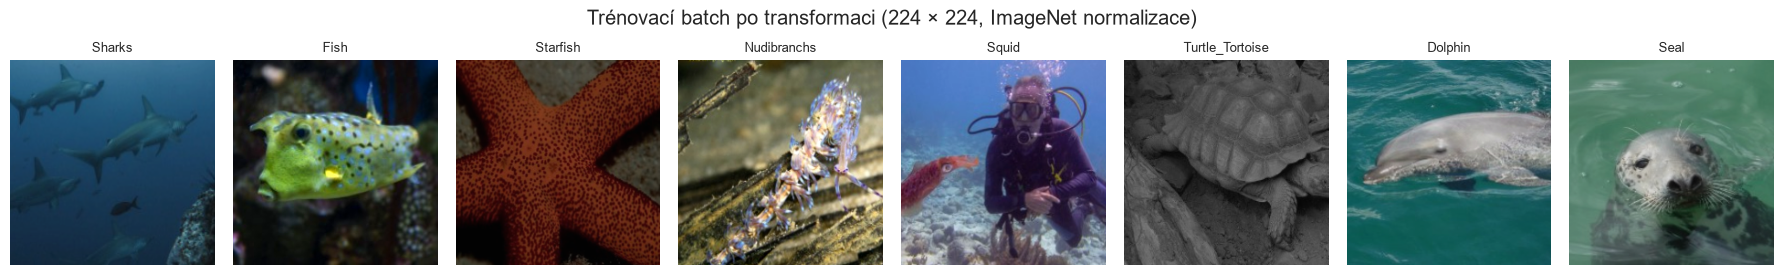

In [6]:
train_tf, eval_tf = build_transforms(img_size=224)
print("train:", train_tf)
print("\neval:", eval_tf)

def denormalize(x):
    # (3, H, W) normalizovaný tenzor -> obrázek 0–1 pro matplotlib
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0)

# jeden batch pro ukázku (num_workers=0 — kvůli 8 obrázkům nemá smysl spouštět workery)
demo_loader = DataLoader(SeaAnimalsDataset(splits["train"], train_tf), batch_size=8, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED))
x_demo, y_demo = next(iter(demo_loader))
print("\nbatch:", tuple(x_demo.shape), x_demo.dtype, "| labely:", tuple(y_demo.shape), y_demo.dtype)

fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for ax, img, lbl in zip(axes, x_demo, y_demo):
    ax.imshow(denormalize(img)); ax.set_title(idx_to_class[lbl.item()], fontsize=9); ax.axis("off")
fig.suptitle("Trénovací batch po transformaci (224 × 224, ImageNet normalizace)")
plt.tight_layout(); plt.show()

## 🎨 CutMix a Mixup — ukázka

Dvě **dynamické augmentace**, které použijeme v E3. Na rozdíl od flipu nebo výřezu nemění jen obrázek,
ale **míchají dva obrázky a jejich labely**:

| Metoda | Obrázek | Label |
|---|---|---|
| **Mixup** | průhledné prolnutí: `lam · A + (1 − lam) · B` | `lam` dílu třídy A + `(1 − lam)` dílu třídy B |
| **CutMix** | do obrázku A se vloží obdélník z obrázku B | podle plochy: kolik % obrázku zůstalo z A |

`lam` se pro každý batch losuje z Beta rozdělení. Loss se pak počítá smíchaně:
`lam · CE(predikce, třída A) + (1 − lam) · CE(predikce, třída B)`.

**Proč to pomáhá:**
- **CutMix** nutí síť rozpoznat zvíře i z **části** těla — nemůže se spoléhat na jeden výrazný detail
  (třeba oko), protože ten může být překrytý.
- **Mixup** učí síť **neodpovídat přehnaně sebejistě** — správná odpověď je „70 % želva, 30 % tuleň“,
  ne „100 % želva“. To je přesně problém, který jsme viděli v M1 (rostoucí val loss = příliš sebejisté chyby).
- Obojí vytváří nekonečně mnoho nových kombinací ⇒ silná regularizace proti přeučení.

### Implementace: modul `src/augment.py`

`mix_batch` dostane celý batch obrázků `x` a labelů `y` a vrátí smíchaný batch, **dva** sloupce labelů
(`y_a` = původní, `y_b` = labely obrázků, se kterými se míchalo) a poměr `lam`. Partnery k míchání vybírá
náhodná permutace téhož batche (`torch.randperm`) — není potřeba načítat další obrázky.

U CutMixu se `lam` po vložení obdélníku **přepočítá podle skutečné plochy** — obdélník u okraje obrázku se ořízne,
takže by jinak label neodpovídal tomu, co je v obrázku vidět.

In [7]:
%%writefile src/augment.py
"""Dynamická augmentace na úrovni batche: CutMix a Mixup (Milestone 2, experiment E3)."""
import math
import random

import numpy as np
import torch


def mix_batch(x, y, mixup_alpha=0.0, cutmix_alpha=0.0, prob=1.0):
    """Smíchá obrázky v batchi s jinými obrázky téhož batche.

    Mixup:  nový obrázek = lam * obrázek_A + (1 - lam) * obrázek_B   (průhledné prolnutí)
    CutMix: do obrázku A se vloží obdélník z obrázku B; lam = podíl plochy, která zůstala z A
    lam se losuje z Beta(alpha, alpha). Label je pak „lam díl třídy A + (1 - lam) dílu třídy B“.

    Vrací (x, y_a, y_b, lam). Bez míchání je y_b = y_a a lam = 1.
    """
    use_mixup, use_cutmix = mixup_alpha > 0, cutmix_alpha > 0
    if not (use_mixup or use_cutmix) or random.random() > prob:
        return x, y, y, 1.0

    # když jsou zapnuté obě metody, pro každý batch se náhodně vybere jedna z nich
    do_cutmix = use_cutmix and (not use_mixup or random.random() < 0.5)
    alpha = cutmix_alpha if do_cutmix else mixup_alpha
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.size(0), device=x.device)     # s kým se který obrázek smíchá

    if do_cutmix:
        H, W = x.shape[2], x.shape[3]
        cut = math.sqrt(1.0 - lam)                         # strana obdélníku tak, aby měl plochu (1 - lam)
        ch, cw = int(H * cut), int(W * cut)
        cy, cx = random.randrange(H), random.randrange(W)  # střed obdélníku
        y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
        x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
        x = x.clone()
        x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1.0 - (y2 - y1) * (x2 - x1) / (H * W)        # oprava: obdélník se mohl oříznout o okraj
    else:
        x = lam * x + (1.0 - lam) * x[perm]

    return x, y, y[perm], lam

Overwriting src/augment.py


In [8]:
import importlib
import src.augment
importlib.reload(src.augment)          # po úpravě souboru načte novou verzi i bez restartu kernelu
from src.augment import mix_batch

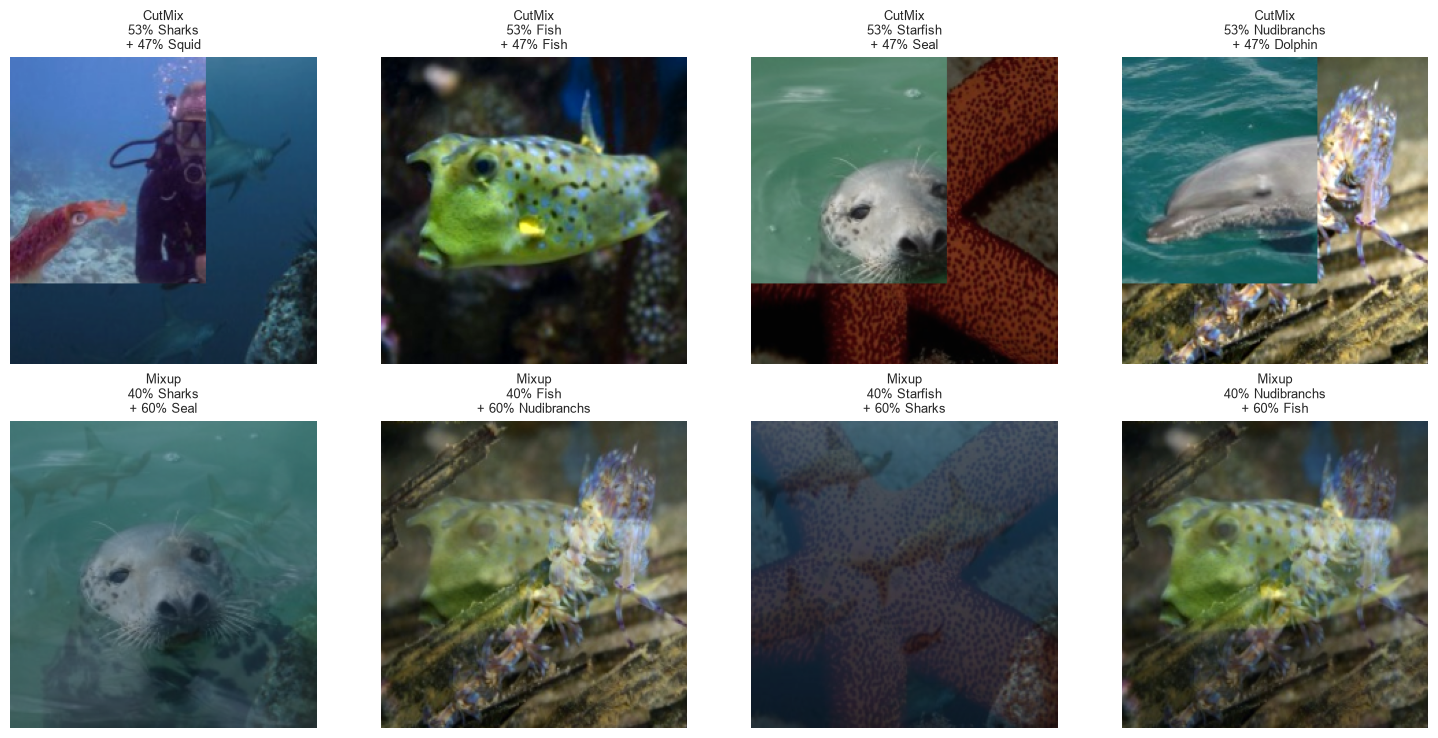

In [9]:
def mix_for_demo(**kwargs):
    # Pro ukázku losujeme znovu, dokud lam nevyjde mezi 0,3 a 0,7 — jinak by smíchání nebylo vidět.
    # Při tréninku se lam NEvybírá: Beta(alpha, alpha) s alpha < 1 má tvar „U“ a často dává lam blízko
    # 0 nebo 1 (obrázek skoro beze změny) — jen občas vznikne výrazně smíchaný obrázek.
    while True:
        out = mix_batch(x_demo, y_demo, **kwargs)
        if 0.3 <= out[3] <= 0.7:
            return out

torch.manual_seed(SEED)
x_cm, ya_cm, yb_cm, lam_cm = mix_for_demo(cutmix_alpha=1.0)
x_mu, ya_mu, yb_mu, lam_mu = mix_for_demo(mixup_alpha=0.4)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for row, (xm, ya, yb, lam, name) in enumerate([(x_cm, ya_cm, yb_cm, lam_cm, "CutMix"),
                                                 (x_mu, ya_mu, yb_mu, lam_mu, "Mixup")]):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(denormalize(xm[col])); ax.axis("off")
        ax.set_title(f"{name}\n{lam:.0%} {idx_to_class[ya[col].item()]}\n"
                     f"+ {1 - lam:.0%} {idx_to_class[yb[col].item()]}", fontsize=9)
plt.tight_layout(); plt.show()

# 🧠 Část 2 — Model: předtrénovaná ResNet-50

Stejně jako ve cvičení 4 použijeme **ResNet-50** z `torchvision` s vahami natrénovanými na **ImageNetu**
(1,28 milionu obrázků, 1 000 tříd; váhy `IMAGENET1K_V2`: 80,9 % top-1 accuracy na ImageNetu).

**Proč ResNet-50:**
- dobře známá architektura ze cvičení — umíme vysvětlit každý krok,
- ImageNet obsahuje i mořská zvířata (žraloky, želvy, medúzy, ryby…) ⇒ naučené vzory jsou pro nás velmi relevantní,
- velikost odpovídá naší GPU: plný fine-tuning se vejde do 8 GB paměti (batch 32, ~6,3 GB).

**Residual connections:** ResNet je postavená z bloků, kde se vstup bloku **přičte k jeho výstupu**
(`výstup = F(x) + x`). Gradient tak může téct „zkratkou“ přímo k nižším vrstvám a jde trénovat i velmi
hluboké sítě (50 vrstev) — bez toho by gradient při průchodu desítkami vrstev slábl.

**Úprava pro naši úlohu:** původní hlava `model.fc` = `Linear(2048 → 1000 tříd ImageNetu)` nahradíme
vlastní `Dropout(0,2) → Linear(2048 → 23)`. Dropout přidáváme jako regularizaci — nová hlava má jen
~47 tisíc vah, ale 23 tříd a málo dat.

Síť si rozdělíme na **bloky**, které budeme postupně odmrazovat. Čím dál od vstupu, tím specifičtější
vzory blok rozpoznává:

| Blok | Co rozpoznává | Výstup (pro vstup 224 × 224) |
|---|---|---|
| `stem` (conv1 + bn1) | hrany, barvy | 64 × 112 × 112 (pak MaxPool → 56 × 56) |
| `layer1` | jednoduché textury | 256 × 56 × 56 |
| `layer2` | složitější textury, vzory | 512 × 28 × 28 |
| `layer3` | části objektů (ploutev, oko, krunýř) | 1024 × 14 × 14 |
| `layer4` | celé objekty, nejvíc specifické pro ImageNet | 2048 × 7 × 7 |
| `fc` (naše hlava) | 23 tříd | 23 |

## 🧱 Modul `src/models.py`

| Funkce | Co dělá | Cvičení 4 |
|---|---|---|
| `build_resnet50` | ResNet-50 s vahami z ImageNetu, `model.fc` nahrazen za `Dropout → Linear(2048 → 23)` | `resnet50(weights=...)`, výměna `model.fc` |
| `get_blocks`, `block_params` | rozdělení sítě na bloky `stem`, `layer1`–`layer4`, `fc` a jejich parametry | `model.named_children()` |
| `set_trainable` | zmrazí vše (`requires_grad = False`) a odmrazí jen vybrané bloky; hlava je trénovatelná vždy | freeze / unfreeze |
| `freeze_bn_stats` | BatchNorm ve zmrazených blocích přepne do `eval()` — nepřepisují se statistiky z ImageNetu | `bn_frozen=True` |
| `count_params` | všechny vs. trénovatelné parametry | `count_params` |
| `param_groups` | každý blok = vlastní skupina parametrů s vlastním learning rate | discriminative LR (parameter groups) |

In [10]:
%%writefile src/models.py
"""Model pro Milestone 2: předtrénovaná ResNet-50 (transfer learning, varianta A).

Navazuje na cvičení 4 (ML_04_TransferLearning_PyTorch): načtení vah z ImageNetu, výměna hlavy
`model.fc`, zmrazení přes `requires_grad = False`, zmrazené BatchNorm statistiky a různé learning
rate pro různé části sítě (parameter groups).
"""
import torch.nn as nn
from torchvision.models import ResNet50_Weights, resnet50

# Části ResNet-50 od vstupu k výstupu. Čím dál od vstupu, tím specifičtější vzory blok rozpoznává:
#   stem (conv1 + bn1)  -> hrany, barvy           (obecné, hodí se pro jakákoliv data)
#   layer1 .. layer4    -> textury -> části -> objekty
#   fc                  -> naše nová hlava pro 23 tříd (náhodné váhy)
BLOCKS = ["stem", "layer1", "layer2", "layer3", "layer4", "fc"]


def build_resnet50(n_classes, dropout=0.2):
    """ResNet-50 s vahami z ImageNetu a novou hlavou Dropout -> Linear(2048 -> n_classes)."""
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    # Původní hlava: Linear(2048 -> 1000 tříd ImageNetu). Nahradíme ji vlastní (nová vrstva je trénovatelná).
    model.fc = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(model.fc.in_features, n_classes),
    )
    return model


def get_blocks(model):
    """Slovník název bloku -> seznam jeho modulů (stem je složený ze dvou modulů)."""
    return {
        "stem": [model.conv1, model.bn1],
        "layer1": [model.layer1],
        "layer2": [model.layer2],
        "layer3": [model.layer3],
        "layer4": [model.layer4],
        "fc": [model.fc],
    }


def block_params(model, name):
    """Všechny parametry jednoho bloku."""
    return [p for module in get_blocks(model)[name] for p in module.parameters()]


def set_trainable(model, trainable_blocks):
    """Zmrazí celou síť a odmrazí jen vyjmenované bloky (hlava `fc` je trénovatelná vždy).

    Zmrazený parametr (requires_grad=False) nedostane gradient, takže ho optimizer nezmění.
    """
    for p in model.parameters():
        p.requires_grad = False
    for name in set(trainable_blocks) | {"fc"}:
        for p in block_params(model, name):
            p.requires_grad = True


def freeze_bn_stats(model):
    """BatchNorm ve zmrazených blocích přepne do eval režimu (bn_frozen ze cvičení 4).

    BatchNorm si kromě vah pamatuje i průměr a rozptyl dat (running statistiky), které se v režimu
    train() přepisují podle aktuálních batchů — i když jsou jeho váhy zmrazené. Ve zmrazených
    blocích chceme zachovat statistiky z ImageNetu, proto je přepneme do eval(). Volá se po
    každém model.train(), protože ten přepne do train režimu celou síť.
    """
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()


def count_params(model):
    """(všechny parametry, trénovatelné parametry) — nejužitečnější kontrola v transfer learningu."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def param_groups(model, lrs):
    """Skupiny parametrů s vlastním learning rate pro každý blok (discriminative learning rates).

    lrs: slovník blok -> lr, např. {"layer3": 1e-5, "layer4": 1e-4, "fc": 1e-3}.
    Do optimizeru dáme rovnou všechny bloky, které budeme během tréninku odmrazovat — dokud je
    blok zmrazený, jeho parametry nemají gradient a optimizer je přeskočí. Po odmrazení se začnou
    učit se svým lr, aniž bychom museli vytvářet nový optimizer.
    """
    return [{"params": block_params(model, name), "lr": lr, "name": name}
            for name, lr in lrs.items()]

Overwriting src/models.py


In [11]:
import importlib
import src.models
importlib.reload(src.models)          # po úpravě souboru načte novou verzi i bez restartu kernelu
from src.models import BLOCKS, block_params, build_resnet50, count_params, set_trainable

In [12]:
model = build_resnet50(N_CLASSES).to(device)
print("Nová hlava:", model.fc)

total, _ = count_params(model)
print(f"\n{'blok':<8} {'parametrů':>12} {'podíl':>7}")
for name in BLOCKS:
    n = sum(p.numel() for p in block_params(model, name))
    print(f"{name:<8} {n:>12,} {n / total:>7.1%}")
print(f"{'celkem':<8} {total:>12,}")

# Kolik parametrů se trénuje při různém odmrazení (= kolik práce má optimizer)
print()
for blocks in [[], ["layer4"], ["layer3", "layer4"], ["stem", "layer1", "layer2", "layer3", "layer4"]]:
    set_trainable(model, blocks)
    print(f"odmrazeno {str(blocks or 'jen hlava'):<52} -> trénovatelných {count_params(model)[1]:>11,}")

# Kontrola tvarů: batch z Části 1 -> 23 logitů
model.eval()
with torch.no_grad():
    out = model(x_demo.to(device))
print("\nvstup", tuple(x_demo.shape), "-> výstup", tuple(out.shape))
assert out.shape == (x_demo.shape[0], N_CLASSES)
del model; torch.cuda.empty_cache()

Nová hlava: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=2048, out_features=23, bias=True)
)

blok        parametrů   podíl
stem            9,536    0.0%
layer1        215,808    0.9%
layer2      1,219,584    5.2%
layer3      7,098,368   30.1%
layer4     14,964,736   63.5%
fc             47,127    0.2%
celkem     23,555,159

odmrazeno jen hlava                                            -> trénovatelných      47,127
odmrazeno ['layer4']                                           -> trénovatelných  15,011,863
odmrazeno ['layer3', 'layer4']                                 -> trénovatelných  22,110,231
odmrazeno ['stem', 'layer1', 'layer2', 'layer3', 'layer4']     -> trénovatelných  23,555,159



vstup (8, 3, 224, 224) -> výstup (8, 23)


> 💡 **Kde jsou parametry:** `layer4` obsahuje **64 %** všech vah sítě, `layer3` dalších 30 %. Odmrazení
> `layer4` tedy znamená skok z 47 tisíc na 15 milionů trénovatelných parametrů — proto se odmrazuje
> opatrně, postupně a s malým learning rate.

# 🔁 Část 2b — Tréninková smyčka (`src/train.py`)

Smyčku z Milestone 1 (`zero_grad` → forward → loss → `backward` → `step`, ruční akumulace metrik) rozšíříme
o to, co potřebují experimenty M2. Modul zapíšeme ve **třech buňkách** — první soubor vytvoří (`%%writefile`),
další dvě ho doplní na konec (`%%writefile -a`).

## 1️⃣ Seed a plánovač learning rate

- **`set_seed`** — pevný seed + deterministické cuDNN ⇒ každý experiment jde zopakovat se stejnými čísly.
- **`make_scheduler`** — **warmup + cosine annealing**. `LambdaLR` násobí základní lr každé skupiny parametrů
  číslem z funkce `factor(step)`:
  - **warmup** (první kroky): násobitel lineárně roste z ~0 na 1. Nová hlava má náhodné váhy a první gradienty
    jsou velké a chaotické — malé první kroky zabrání tomu, aby „rozbily“ předtrénované vrstvy,
  - **cosine**: násobitel plynule klesá z 1 k 0 po křivce kosinu — na začátku velké kroky (rychlý pokrok),
    na konci malé (jemné doladění).
  - Plánovač se volá **po každém batchi** (ne po epoše) ⇒ warmup může trvat třeba jen jednu epochu a křivka je hladká.
  - Násobitel je **stejný pro všechny skupiny** ⇒ poměry learning rate mezi bloky (discriminative LR) zůstávají.

In [13]:
%%writefile src/train.py
"""Trénink pro Milestone 2: warmup + cosine, tréninková smyčka, postupné odmrazování a logy experimentů.

Každý experiment je popsaný jedním slovníkem `config` a jeho výsledky se ukládají do runs/<name>/:
    config.json  — kompletní nastavení (pro reprodukci)
    log.csv      — metriky po každé epoše
    best.pt      — váhy z epochy s nejlepší validační accuracy (mimo git)
Když už experiment se stejnou konfigurací proběhl, fit() ho netrénuje znovu, jen načte výsledky.
"""
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from src.augment import mix_batch
from src.data import build_transforms, make_loaders
from src.models import build_resnet50, count_params, freeze_bn_stats, param_groups, set_trainable


def set_seed(seed):
    """Pevný seed + deterministické cuDNN => stejná čísla při každém spuštění (jako v M1)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_scheduler(optimizer, total_steps, warmup_steps):
    """Násobitel lr podle kroku: 0 -> 1 lineárně během warmupu, pak po kosinu z 1 k 0.

    Plánovač se volá po každém batchi. Násobitel se aplikuje na základní lr KAŽDÉ skupiny
    parametrů zvlášť, takže poměry mezi bloky (discriminative LR) zůstávají zachované.
    """
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)

Overwriting src/train.py


## 2️⃣ Jedna epocha tréninku a validace

**`train_one_epoch`** — stejná smyčka jako v M1, se třemi rozšířeními:
1. **`freeze_bn_stats(model)`** hned po `model.train()` — `model.train()` přepne do trénovacího režimu celou síť,
   včetně BatchNorm ve zmrazených blocích. Ty vrátíme do `eval()`, aby si nepřepsaly statistiky z ImageNetu.
2. **CutMix / Mixup** (`mix_batch`) — batch se smíchá ještě před průchodem sítí. Loss se pak počítá
   **stejně smíchaná**: `lam · CE(logity, y_a) + (1 − lam) · CE(logity, y_b)`. Bez míchání je `lam = 1` a vzorec
   se zjednoduší na obyčejnou CE.
3. **`scheduler.step()`** po každém kroku optimizeru.

Accuracy u smíchaného batche počítáme **váženou** stejně jako label — predikce třídy A u obrázku, který je ze 70 %
třída A, se počítá jako 0,7 zásahu.

**`evaluate`** — beze změny oproti M1: `model.eval()` + `torch.no_grad()`, žádné míchání, žádná úprava vah.

In [14]:
%%writefile -a src/train.py


# ---------------------------------------------------------------------------------------------
# Jedna epocha tréninku / validace
# ---------------------------------------------------------------------------------------------
def train_one_epoch(model, loader, criterion, optimizer, scheduler, device, mix_cfg=None):
    model.train()
    freeze_bn_stats(model)                  # BatchNorm ve zmrazených blocích zůstane v eval režimu
    mix_cfg = mix_cfg or {}
    total_loss, correct, n = 0.0, 0.0, 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        x, y_a, y_b, lam = mix_batch(x, y, **mix_cfg)

        optimizer.zero_grad()
        logits = model(x)
        # loss smíchaného obrázku = stejně smíchané loss vůči oběma labelům
        loss = lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)
        loss.backward()
        optimizer.step()
        scheduler.step()                    # plánovač po každém batchi (warmup je v krocích)

        pred = logits.argmax(dim=1)
        total_loss += loss.item() * y.size(0)
        # u smíchaného batche počítáme zásah vážený stejně jako label
        correct += (lam * (pred == y_a).sum() + (1.0 - lam) * (pred == y_b).sum()).item()
        n += y.size(0)

    return total_loss / n, correct / n


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            logits = model(x)
            total_loss += criterion(logits, y).item() * y.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

Appending to src/train.py


## 3️⃣ Celý experiment: `fit()`

Jeden experiment = jeden slovník `config`. `fit()`:
1. **Zkontroluje `runs/<jméno>/`** — pokud tam jsou uložené váhy a log se **stejnou** konfigurací, experiment
   netrénuje, jen načte výsledky. Pokud existuje s **jinou** konfigurací, skončí chybou (aby se výsledky omylem
   nepřepsaly).
2. Uloží **`config.json`** — kompletní nastavení experimentu (reprodukovatelnost).
3. Vytvoří model, DataLoadery, optimizer **AdamW se skupinami parametrů** (každý blok vlastní lr) a plánovač.
   Do optimizeru dá rovnou **všechny** bloky z `lrs` — zmrazené parametry nemají gradient, takže je optimizer
   přeskočí; po odmrazení se začnou učit, aniž by bylo potřeba vytvářet nový optimizer.
4. Každou epochu: podle plánu **odmrazí bloky** (`blocks_for_epoch`), natrénuje, zvaliduje, uloží váhy, pokud je
   val accuracy nejlepší dosud, a **průběžně zapisuje `log.csv`** (log přežije i přerušený trénink).
5. Na konci načte váhy z nejlepší epochy.

Trénovací loss používá label smoothing (pokud je zapnutý), **validační ne** — validační loss je tak srovnatelná
napříč experimenty.

In [15]:
%%writefile -a src/train.py


# ---------------------------------------------------------------------------------------------
# Celý experiment
# ---------------------------------------------------------------------------------------------
def blocks_for_epoch(unfreeze_schedule, epoch):
    """Které bloky jsou v dané epoše odmrazené. Plán {"1": [], "4": ["layer4"]} znamená:
    epochy 1–3 jen hlava, od epochy 4 navíc layer4."""
    start = max(int(e) for e in unfreeze_schedule if int(e) <= epoch)
    return unfreeze_schedule[str(start)]


def fit(config, splits, n_classes, device, runs_dir="runs", retrain=False):
    """Natrénuje (nebo načte) experiment. Vrací (model s nejlepšími vahami, log jako DataFrame)."""
    cfg = json.loads(json.dumps(config))                 # kopie ve stejné podobě, jakou má config.json
    run_dir = Path(runs_dir) / cfg["name"]
    cfg_path, log_path, ckpt_path = run_dir / "config.json", run_dir / "log.csv", run_dir / "best.pt"

    # --- experiment už proběhl: jen načíst -------------------------------------------------------
    if not retrain and ckpt_path.exists() and log_path.exists():
        saved = json.loads(cfg_path.read_text(encoding="utf-8"))
        if saved != cfg:
            raise ValueError(f"runs/{cfg['name']} už existuje s jinou konfigurací — "
                             "změň name, nebo spusť s retrain=True.")
        model = build_resnet50(n_classes, dropout=cfg["dropout"]).to(device)
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        log = pd.read_csv(log_path)
        print(f"[{cfg['name']}] načteno z {run_dir} (nejlepší val acc {log['val_acc'].max():.1%})")
        return model, log

    # --- nový trénink ---------------------------------------------------------------------------
    set_seed(cfg["seed"])
    model = build_resnet50(n_classes, dropout=cfg["dropout"]).to(device)   # až po seedu => stejná hlava
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg_path.write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding="utf-8")

    train_tf, eval_tf = build_transforms(cfg["img_size"], cfg["random_erasing"])
    loaders = make_loaders(splits, train_tf, eval_tf, cfg["batch_size"], cfg["num_workers"])

    optimizer = torch.optim.AdamW(param_groups(model, cfg["lrs"]), weight_decay=cfg["weight_decay"])
    head_group = next(g for g in optimizer.param_groups if g["name"] == "fc")   # pro log lr hlavy
    steps_per_epoch = len(loaders["train"])
    scheduler = make_scheduler(optimizer, cfg["epochs"] * steps_per_epoch,
                               int(cfg["warmup_epochs"] * steps_per_epoch))
    train_crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    eval_crit = nn.CrossEntropyLoss()                    # validace bez smoothingu => srovnatelná loss
    mix_cfg = {"mixup_alpha": cfg["mixup_alpha"], "cutmix_alpha": cfg["cutmix_alpha"],
               "prob": cfg["mix_prob"]}

    rows, best_acc, prev_blocks = [], -1.0, None
    t_start = time.perf_counter()
    for epoch in range(1, cfg["epochs"] + 1):
        blocks = blocks_for_epoch(cfg["unfreeze_schedule"], epoch)
        if blocks != prev_blocks:
            set_trainable(model, blocks)
            print(f"[{cfg['name']}] epocha {epoch}: odmrazeno {blocks or 'nic'} + hlava "
                  f"-> trénovatelných {count_params(model)[1]:,} parametrů")
            prev_blocks = blocks

        t0 = time.perf_counter()
        lr_head = head_group["lr"]                        # lr hlavy na začátku epochy (pro graf)
        tr_loss, tr_acc = train_one_epoch(model, loaders["train"], train_crit, optimizer,
                                          scheduler, device, mix_cfg)
        va_loss, va_acc = evaluate(model, loaders["val"], eval_crit, device)

        is_best = va_acc > best_acc
        if is_best:
            best_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)
        rows.append({"epoch": epoch, "blocks": "+".join(blocks) or "-", "lr_head": lr_head,
                     "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss,
                     "val_acc": va_acc, "seconds": round(time.perf_counter() - t0, 1)})
        pd.DataFrame(rows).to_csv(log_path, index=False)  # průběžně — log přežije i přerušený trénink
        print(f"[{cfg['name']}] epocha {epoch:2d}/{cfg['epochs']} | train loss {tr_loss:.3f} acc {tr_acc:6.1%} "
              f"| val loss {va_loss:.3f} acc {va_acc:6.1%} | {rows[-1]['seconds']:5.1f} s{' ⭐' if is_best else ''}",
              flush=True)

    print(f"[{cfg['name']}] hotovo za {(time.perf_counter() - t_start) / 60:.1f} min, "
          f"nejlepší val acc {best_acc:.1%}")
    del loaders                                           # ukončí workery DataLoaderu
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, pd.DataFrame(rows)

Appending to src/train.py


In [16]:
import importlib
import src.train
importlib.reload(src.train)          # po úpravě souboru načte novou verzi i bez restartu kernelu
from src.train import fit

# 🧊 Část 3 — Experiment E1: zmrazená síť, trénuje se jen hlava

První krok transfer learningu (cvičení 4: *feature extraction phase*): **celou předtrénovanou síť zmrazíme**
a trénujeme jen novou hlavu. ResNet-50 tak slouží jako hotový „extraktor vlastností“ — z každého obrázku
spočítá 2 048 čísel a hlava se z nich učí rozhodnout o třídě.

**Co tím měříme:** kolik přinese **samotné předtrénování** bez jakéhokoli přizpůsobení sítě našim datům.

| Nastavení | Hodnota | Proč |
|---|---|---|
| odmrazené bloky | žádné (jen hlava, 47 tisíc parametrů) | čistý efekt předtrénovaných vlastností |
| BatchNorm | statistiky zmrazené (`freeze_bn_stats`) | zachováme statistiky z ImageNetu (`bn_frozen` ze cvičení) |
| optimizer | AdamW, lr = 1e-3, weight decay 0,01 | hlava je nová (náhodné váhy) ⇒ může se učit rychle |
| plánovač lr | 1 epocha warmup + cosine | viz Část 4; tady hlavně pro konzistenci s dalšími experimenty |
| epochy | 8 | hlava je malá, učí se rychle |
| augmentace | jako vylepšený model v M1 (výřez, flip, barvy) | bez CutMix / Mixup — ty přidáme v E3 |
| batch | 32 | stejný ve všech experimentech (plný fine-tuning se větší nevejde do paměti) |

In [17]:
CONFIG_E1 = {
    "name": "E1_head_only",
    "seed": SEED, "img_size": 224, "batch_size": 32, "num_workers": 4,
    "epochs": 8, "warmup_epochs": 1,
    "unfreeze_schedule": {"1": []},           # celou dobu jen hlava
    "lrs": {"fc": 1e-3},
    "weight_decay": 0.01, "dropout": 0.2,
    "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0, "mix_prob": 0.0,
    "random_erasing": 0.0,
}

model_e1, log_e1 = fit(CONFIG_E1, splits, N_CLASSES, device, retrain=RETRAIN)
results["E1 jen hlava"] = {"val_acc": log_e1["val_acc"].max()}
log_e1

[E1_head_only] načteno z runs\E1_head_only (nejlepší val acc 85.9%)


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.287842,0.512664,1.285960,0.796469,76.7
1,2,-,0.001000,0.916846,0.826484,0.716311,0.835704,26.0
2,3,-,0.000950,0.633139,0.852549,0.593290,0.847474,28.2
3,4,-,0.000812,0.546139,0.865160,0.543491,0.851398,26.7
4,5,-,0.000611,0.503900,0.868839,0.520077,0.854340,26.6
5,6,-,0.000389,0.483982,0.874514,0.509651,0.858754,26.1
6,7,-,0.000188,0.460328,0.885339,0.505159,0.859245,26.0
7,8,-,0.000050,0.459047,0.880820,0.504624,0.858264,25.8


### 📈 Křivky učení

Funkci pro kreslení křivek budeme používat u všech experimentů. Kreslí loss, accuracy a learning rate hlavy
po epochách; svislé čáry označují epochy, kdy se odmrazil další blok.

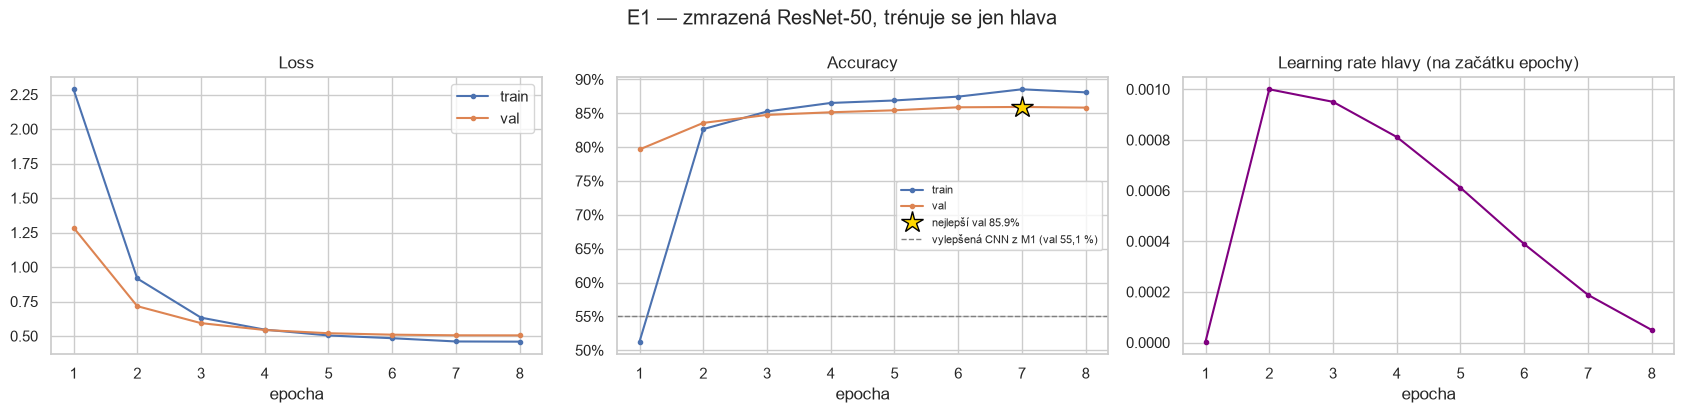

In [18]:
def plot_log(log, title):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    ep = log["epoch"]
    axes[0].plot(ep, log["train_loss"], "o-", ms=3, label="train")
    axes[0].plot(ep, log["val_loss"], "o-", ms=3, label="val")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epocha"); axes[0].legend()

    axes[1].plot(ep, log["train_acc"], "o-", ms=3, label="train")
    axes[1].plot(ep, log["val_acc"], "o-", ms=3, label="val")
    best = log["val_acc"].idxmax()
    axes[1].plot(log.loc[best, "epoch"], log.loc[best, "val_acc"], "*", color="gold", ms=16,
                 markeredgecolor="black", label=f"nejlepší val {log.loc[best, 'val_acc']:.1%}")
    axes[1].axhline(0.551, color="gray", ls="--", lw=1, label="vylepšená CNN z M1 (val 55,1 %)")
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("epocha"); axes[1].legend(fontsize=8)

    axes[2].plot(ep, log["lr_head"], "o-", ms=3, color="purple")
    axes[2].set_title("Learning rate hlavy (na začátku epochy)"); axes[2].set_xlabel("epocha")

    for i in range(1, len(log)):                          # změna odmrazených bloků
        if log["blocks"].iloc[i] != log["blocks"].iloc[i - 1]:
            for ax in axes:
                ax.axvline(log["epoch"].iloc[i] - 0.5, color="red", ls=":", lw=1)
            prev = set(log["blocks"].iloc[i - 1].split("+"))
            added = [b for b in log["blocks"].iloc[i].split("+") if b not in prev]
            text = "+ zbytek sítě" if len(added) > 1 else "+ " + added[0]
            axes[1].text(log["epoch"].iloc[i] - 0.4, axes[1].get_ylim()[0] + 0.02, text,
                         color="red", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_log(log_e1, "E1 — zmrazená ResNet-50, trénuje se jen hlava")

### 📝 Interpretace E1

- **Obrovský skok:** nejlepší val accuracy **85,9 %** (7. epocha) proti **55,1 %** u nejlepší sítě z M1
  (+30,8 p. b.) — a to se trénovala jen nová hlava se **47 tisíci** parametry (síť z M1 jich měla 1,18 milionu).
  Vlastnosti, které se ResNet-50 naučila na ImageNetu (hrany, textury, tvary, části zvířat), se tedy na
  podvodní fotky **přenášejí velmi dobře**. Přesně to je smysl transfer learningu.
- **Už po první epoše 79,6 %** — hlava se jen učí, jak z hotových 2 048 vlastností poskládat 23 tříd.
- **Val accuracy je v 1. epoše vyšší než train** (79,6 % vs. 51,3 %): train accuracy je průměr přes celou
  epochu, během které se model teprve učil (a lr při warmupu stoupal z nuly). Validace se měří až na konci
  epochy. Navíc train data jsou augmentovaná a při tréninku je zapnutý Dropout.
- **Žádné přeučení:** train 88 % vs. val 86 %, val loss klesá až do konce (0,505). Hlava má málo parametrů
  a nemá si co „zapamatovat“.
- **Strop:** od ~5. epochy se val accuracy zastaví kolem 85–86 %. Vlastnosti z ResNet-50 jsou **pevné**
  (zmrazené) a naučené pro ImageNet — hlava z nich víc nevytěží. Další zlepšení vyžaduje **přizpůsobit
  samotné vlastnosti našim datům** ⇒ odmrazit část sítě (experiment E2).
- **Rychlost:** ~26 s na epochu (první epocha 77 s kvůli startu workerů), celkem 4,4 min.

# 🔥 Část 4 — Experiment E2: postupné odmrazování a různé learning rate

E1 narazil na strop ~86 %, protože vlastnosti sítě byly **pevné**. V E2 je necháme **přizpůsobit našim datům**
(*fine-tuning*). Dělat to ale musíme opatrně — předtrénované váhy jsou cenné a velké kroky optimizeru by je
mohly „rozbít“ (tzv. *catastrophic forgetting*).

## 🧊➜🔥 Postupné odmrazování (gradual unfreezing)

| Epochy | Odmrazeno | Trénovatelných parametrů | Proč |
|---|---|---|---|
| 1–3 | jen hlava | 47 tis. | hlava má na začátku **náhodné váhy** ⇒ její gradienty jsou velké a nesmyslné. Nejdřív ji „usadíme“ (jako E1), aby do sítě neposílala šum |
| 4–6 | + `layer4` | 15,0 mil. | nejvyšší blok má vlastnosti **nejvíc specifické pro ImageNet** ⇒ potřebuje přizpůsobit nejvíc |
| 7–9 | + `layer3` | 22,1 mil. | části objektů (ploutve, krunýře…) |
| 10–15 | celá síť | 23,6 mil. | nakonec jemně doladíme i obecné vrstvy |

Odmrazujeme **od konce sítě k začátku**: nižší vrstvy (hrany, textury) jsou obecné a fungují pro jakékoliv
fotky, takže je měníme nejméně a nejpozději.

## 🎚️ Různé learning rate pro různé bloky (discriminative learning rates)

Stejná myšlenka jako u odmrazování, ale pro velikost kroku — každý blok má vlastní **skupinu parametrů**
v optimizeru (cvičení 4: *parameter groups*):

| Blok | lr | Proč |
|---|---|---|
| `fc` (hlava) | 1e-3 | nová vrstva, učí se od nuly ⇒ velké kroky |
| `layer4` | 1e-4 | 10× méně — přizpůsobuje se, ale nesmí zapomenout, co umí |
| `layer3` | 3e-5 | |
| `layer2`, `layer1`, `stem` | 1e-5 | obecné vlastnosti — jen nepatrné doladění (lr ze cvičení 4 pro fine-tuning celé sítě) |

> 💡 Optimizer dostane **všechny skupiny hned od začátku**. Dokud je blok zmrazený, jeho parametry nemají
> gradient a optimizer je přeskočí. Po odmrazení se začnou učit se svým lr — nemusíme vytvářet nový
> optimizer a neztratí se jeho vnitřní stav (průměry gradientů v AdamW).

## 📉 Plánovač: warmup + cosine annealing

Násobitel learning rate (stejný pro všechny skupiny, takže poměry mezi bloky zůstávají):
- **warmup (1. epocha):** lineárně z ~0 na 1 — první kroky s náhodnou hlavou jsou opatrné,
- **cosine (zbytek):** plynulý pokles po křivce kosinu z 1 k 0 — na začátku velké kroky (rychlý pokrok),
  na konci malé (jemné doladění, model se „usadí“ v dobrém minimu).

Po kroku každého batche se lr přepočítá. Když se v 4. epoše odmrazí `layer4`, začne s lr = 1e-4 × aktuální
násobitel — díky tomu se nové bloky zapojují už s mírně sníženým lr.

## ⚙️ Ostatní nastavení
Stejné jako E1 (AdamW, weight decay 0,01, dropout 0,2, augmentace z M1, batch 32), **bez** CutMix / Mixup
a label smoothingu — ty přidá E3. Změna oproti E1 je tedy jen v odmrazování a learning rate ⇒ rozdíl
výsledků můžeme přičíst právě fine-tuningu.

In [19]:
ALL_BLOCKS = ["stem", "layer1", "layer2", "layer3", "layer4"]

CONFIG_E2 = {
    "name": "E2_gradual_unfreeze",
    "seed": SEED, "img_size": 224, "batch_size": 32, "num_workers": 4,
    "epochs": 15, "warmup_epochs": 1,
    "unfreeze_schedule": {
        "1": [],                           # epochy 1–3: jen hlava
        "4": ["layer4"],                   # 4–6
        "7": ["layer3", "layer4"],         # 7–9
        "10": ALL_BLOCKS,                  # 10–15: celá síť
    },
    "lrs": {"stem": 1e-5, "layer1": 1e-5, "layer2": 1e-5, "layer3": 3e-5, "layer4": 1e-4, "fc": 1e-3},
    "weight_decay": 0.01, "dropout": 0.2,
    "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0, "mix_prob": 0.0,
    "random_erasing": 0.0,
}

model_e2, log_e2 = fit(CONFIG_E2, splits, N_CLASSES, device, retrain=RETRAIN)
results["E2 postupné odmrazování"] = {"val_acc": log_e2["val_acc"].max()}
log_e2

[E2_gradual_unfreeze] načteno z runs\E2_gradual_unfreeze (nejlepší val acc 90.2%)


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.287842,0.512664,1.285960,0.796469,72.0
1,2,-,0.001000,0.916070,0.826590,0.714003,0.836194,26.0
2,3,-,0.000987,0.628922,0.852759,0.586551,0.848455,26.0
3,4,layer4,0.000950,0.462412,0.864635,0.407192,0.883276,35.0
4,5,layer4,0.000891,0.240980,0.930215,0.392330,0.890633,35.1
5,6,layer4,0.000812,0.140293,0.959327,0.418559,0.887690,34.7
6,7,layer3+layer4,0.000717,0.172063,0.945560,0.431381,0.890633,49.8
7,8,layer3+layer4,0.000611,0.089512,0.973305,0.459098,0.886219,50.7
8,9,layer3+layer4,0.000500,0.060942,0.981503,0.453786,0.892104,49.7
9,10,stem+layer1+layer2+layer3+layer4,0.000389,0.099678,0.970573,0.461976,0.892594,87.9


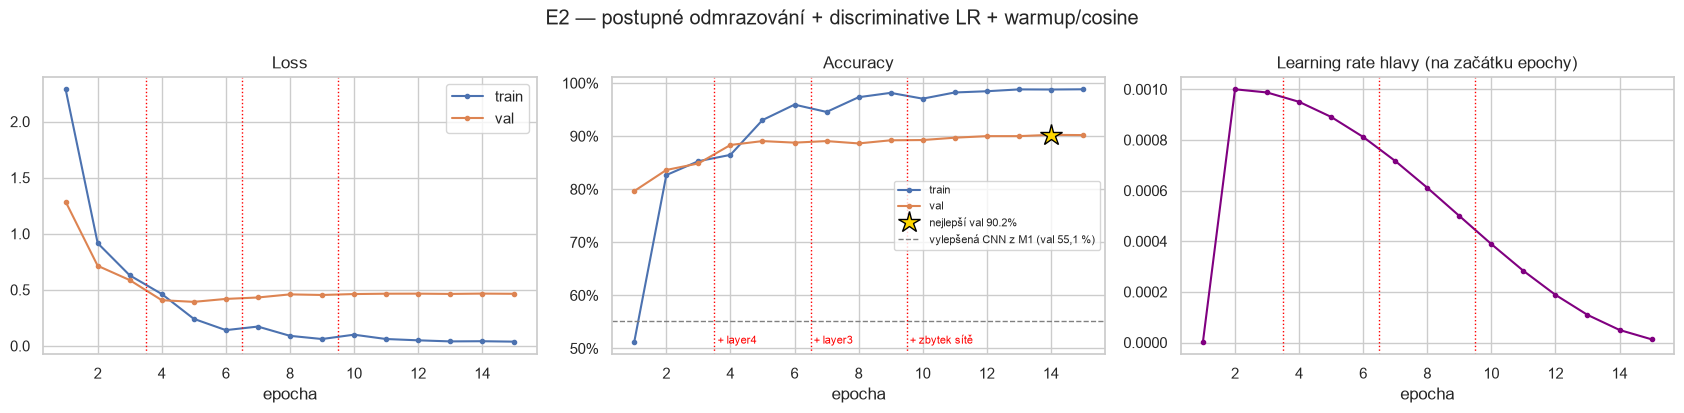

In [20]:
plot_log(log_e2, "E2 — postupné odmrazování + discriminative LR + warmup/cosine")

### 📝 Interpretace E2

- **Výsledek:** nejlepší val accuracy **90,2 %** (14. epocha) — o **+4,3 p. b.** víc než E1 (85,9 %).
  Přizpůsobení předtrénovaných vlastností našim datům tedy pomohlo.
- **Epochy 1–3 jsou téměř shodné s E1** (stejný seed, jen hlava) — to je kontrola, že rozdíl dál způsobuje
  opravdu odmrazování. Drobné rozdíly jsou jen v lr (kosinová křivka je v E2 roztažená na 15 epoch).
- **Kolik přinesl který krok:**

  | Krok | Val accuracy (konec fáze) | Přínos | Čas epochy |
  |---|---|---|---|
  | jen hlava (ep. 1–3) | 84,8 % | — | 26 s |
  | + `layer4` (ep. 4–6) | 88,8 % (max 89,1 %) | **+4,0 p. b.** — hned po odmrazení skok o 3,5 p. b. | 35 s |
  | + `layer3` (ep. 7–9) | 89,2 % | +0,4 p. b. | 50 s |
  | + zbytek sítě (ep. 10–15) | 90,2 % | +1,0 p. b. | 88 s |

  ⇒ **Nejvíc pomohl `layer4`** — obsahuje nejvíc parametrů (64 %) a vlastnosti nejvíc specifické pro
  ImageNet, které bylo potřeba přizpůsobit. Každý další blok přidá méně a stojí víc času
  (celá síť ~3,4× pomalejší než jen hlava) — přesně odpovídá tomu, že nižší vrstvy jsou obecné.
- **Objevilo se přeučení:**
  - train accuracy vystoupala na **98,8 %**, validační zůstala na ~90 % (rozdíl ~9 p. b.; v E1 jen 2 p. b.),
  - **val loss je nejnižší v 5. epoše (0,39)** a pak mírně **stoupá** (0,46), i když val accuracy ještě roste.
    Model tedy klasifikuje správně o něco víc obrázků, ale u chybných predikcí je **čím dál sebejistější** —
    stejný jev jako u baseline v M1, jen mnohem slabší.
  - Příčina: 23,6 milionu odmrazených parametrů na ~9,5 tisíce obrázků ⇒ síť si trénovací data postupně
    zapamatuje (train loss 0,04).
- **Warmup + cosine** funguje podle plánu: lr hlavy během 1. epochy vystoupá na 1e-3 a pak plynule klesá.
  Malý lr na konci (ep. 12–15) „usadí“ model — val accuracy se ustálí na ~90 %.

➡️ **Co z toho plyne pro E3:** síť má dost kapacity, problém je přeučení ⇒ přidáme **silnější regularizaci**
(CutMix / Mixup, Random Erasing, label smoothing), která by měla zmenšit rozdíl train vs. val a hlavně
**snížit sebejistotu u chyb** (val loss).

# 🛡️ Část 5 — Experiment E3: regularizace (CutMix / Mixup, Random Erasing, label smoothing)

E2 ukázal, že síť má **dost kapacity**, ale **přeučuje se** (train 98,8 % vs. val 90 %, val loss od 5. epochy
roste). E3 proto přidává **regularizaci** — techniky, které ztěžují zapamatování trénovacích dat.
**Všechno ostatní zůstává stejné jako v E2** (odmrazování, learning rate, plánovač, 15 epoch), takže rozdíl
výsledků lze přičíst právě regularizaci.

| Technika | Nastavení | Jak funguje | Co řeší |
|---|---|---|---|
| **CutMix** | α = 1,0 | do obrázku vloží obdélník z jiného obrázku, label se smíchá podle plochy | síť musí poznat zvíře i z **části** těla |
| **Mixup** | α = 0,2 | průhledně prolne dva obrázky, label ve stejném poměru | **méně sebejisté** predikce, plynulejší rozhodovací hranice mezi třídami |
| (kombinace) | míchá se **50 %** batchů, pokaždé náhodně jedna z metod | | polovina batchů zůstane čistá ⇒ síť se učí i na skutečných obrázcích |
| **Random Erasing** | p = 0,25 | v každém 4. obrázku vymaže náhodný obdélník (po normalizaci) | síť se nespoléhá na jedno konkrétní místo obrázku |
| **Label smoothing** | 0,1 | cíl pro správnou třídu je 0,9 místo 1,0, zbytek se rozdělí mezi ostatní třídy | model **není přehnaně sebejistý** — přímo míří na rostoucí val loss z E2 |

**Proč tyto hodnoty:** α = 1,0 pro CutMix (rovnoměrné losování velikosti výřezu) a α = 0,2 pro Mixup
(většinou jen slabé prolnutí) jsou běžná výchozí nastavení z původních článků. Label smoothing 0,1 a Random
Erasing p = 0,25 jsou také standardní výchozí hodnoty. Na malém datasetu je nechceme přehánět —
**příliš silná regularizace** by zpomalila učení natolik, že by 15 epoch nestačilo.

> 💡 **Train accuracy bude nižší než v E2** — smíchané a částečně vymazané obrázky jsou těžší a u smíchaných
> batchů se accuracy počítá vážená poměrem `lam`. To je u regularizace žádoucí. Důležitá je **validační**
> accuracy a loss (validační data se nemíchají a loss se počítá bez label smoothingu ⇒ je přímo srovnatelná s E1/E2).

In [21]:
CONFIG_E3 = {
    **CONFIG_E2,                               # vše stejné jako E2 ...
    "name": "E3_regularization",
    "label_smoothing": 0.1,                    # ... plus regularizace
    "mixup_alpha": 0.2, "cutmix_alpha": 1.0, "mix_prob": 0.5,
    "random_erasing": 0.25,
}

model_e3, log_e3 = fit(CONFIG_E3, splits, N_CLASSES, device, retrain=RETRAIN)
results["E3 + regularizace"] = {"val_acc": log_e3["val_acc"].max()}
log_e3

[E3_regularization] načteno z runs\E3_regularization (nejlepší val acc 91.0%)


,epoch,blocks,lr_head,train_loss,train_acc,val_loss,val_acc,seconds
0,1,-,0.000003,2.528440,0.440499,1.457331,0.795488,73.3
1,2,-,0.001000,1.589558,0.717817,0.868299,0.837666,25.8
2,3,-,0.000987,1.437061,0.737942,0.737765,0.853850,26.0
3,4,layer4,0.000950,1.341572,0.760337,0.536560,0.880824,35.8
4,5,layer4,0.000891,1.197441,0.812107,0.458536,0.894066,35.8
5,6,layer4,0.000812,1.119967,0.840445,0.489573,0.889161,36.0
6,7,layer3+layer4,0.000717,1.104920,0.847945,0.495503,0.896518,50.7
7,8,layer3+layer4,0.000611,1.090536,0.849219,0.482152,0.901913,50.9
8,9,layer3+layer4,0.000500,1.016644,0.875131,0.446809,0.907308,50.2
9,10,stem+layer1+layer2+layer3+layer4,0.000389,1.098205,0.845506,0.472258,0.904365,88.1


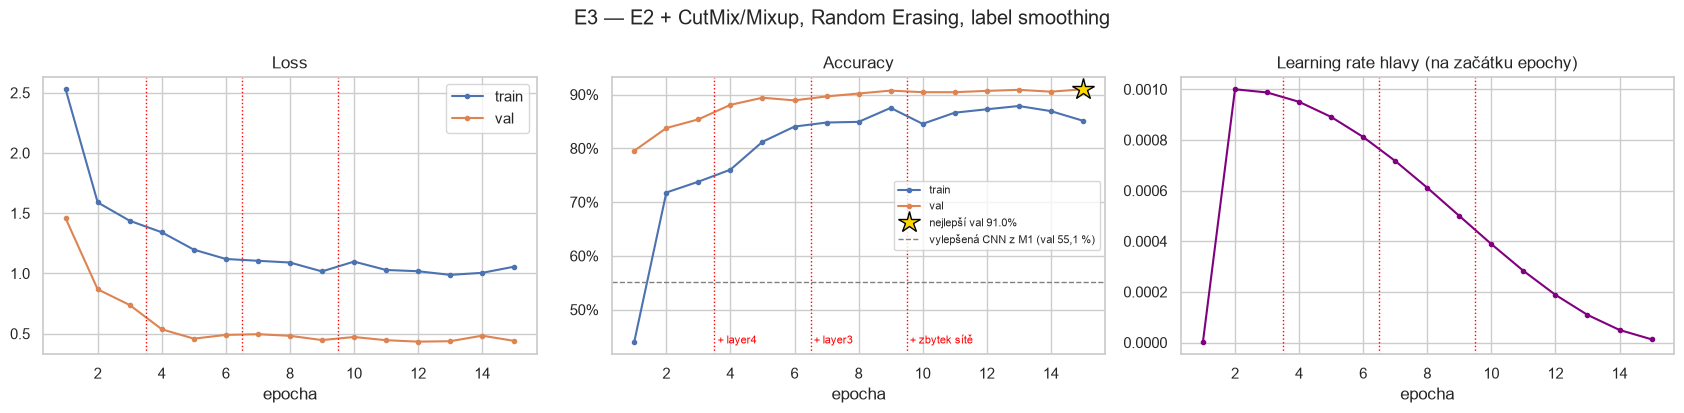

In [22]:
plot_log(log_e3, "E3 — E2 + CutMix/Mixup, Random Erasing, label smoothing")

### 📝 Interpretace E3

| | E2 (bez regularizace) | E3 (+ regularizace) |
|---|---|---|
| Nejlepší val accuracy | 90,2 % (ep. 14) | **91,0 %** (ep. 15) |
| Val loss — minimum | 0,39 (ep. 5) | 0,43 (ep. 12) |
| Val loss — na konci | 0,46 (**rostla** od 5. epochy) | **0,44** (bez růstu, kolísá 0,43–0,50) |
| Train accuracy na konci | 98,8 % | 85,1 % (smíchaná data — není přímo srovnatelná) |

- **Hlavní efekt: přeučení zmizelo.** V E2 val loss od 5. epochy rostla (model byl u chyb stále sebejistější).
  V E3 se po odmrazení `layer4` drží kolem 0,44–0,49 a **nestoupá** až do konce tréninku. Train loss zůstává
  vysoko (~1,0), protože smíchané a vymazané obrázky si síť zapamatovat nemůže.
- **Val accuracy +0,8 p. b.** (90,2 → 91,0 %). To je ~16 obrázků z 2 039 navíc správně. Rozdíl je **malý** a
  máme jen jeden běh se stejným seedem, takže část rozdílu může být náhoda — **nelze ho brát jako jednoznačné
  zlepšení přesnosti**. Jednoznačnější je zlepšení **chování** modelu (val loss).
- **Val loss není s E2 úplně srovnatelná:** model s label smoothingem se učí dávat správné třídě ~90 %, ne 100 %,
  takže i u správných predikcí má vyšší loss (−ln 0,9 ≈ 0,1 místo ~0). Že je přesto val loss na konci nižší
  než v E2, znamená, že výrazně klesla loss u **chybných** predikcí — model už není přehnaně sebejistý, když se mýlí.
- **Proč je train accuracy nižší než validační:** u smíchaných batchů se zásah počítá vážený poměrem `lam`
  (model nemůže „trefit“ 100 % obrázku, který je ze 60 % želva a ze 40 % tuleň) a Random Erasing občas zakryje
  podstatnou část zvířete. Validační obrázky jsou čisté.
- **Model se pořád mírně zlepšuje** — nejlepší epocha je ta poslední. Regularizovaný model se učí pomaleji,
  takže by mu pravděpodobně prospěl delší trénink.
- **Čas:** stejný jako E2 (15,2 min) — CutMix / Mixup / Random Erasing jsou výpočetně zanedbatelné.

➡️ **Závěr:** regularizace splnila hlavní cíl — **odstranila přeučení** a model je spolehlivější v tom, jak
moc si je jistý. Na přesnosti přidala jen málo, protože už E2 byl blízko stropu, který ResNet-50 na 224 px
a ~9,5 tisíci obrázků umožňuje.

# 📊 Část 6 — Srovnání experimentů

## 🧾 Konfigurace experimentů

Každý experiment má svou konfiguraci uloženou v `runs/<jméno>/config.json`. Tabulku níže **načítáme přímo
z těchto souborů** — je to tedy přesně to nastavení, se kterým se trénovalo, a podle něj jde každý experiment
zopakovat (`fit(config, ...)` se stejným seedem dá stejná čísla). Zobrazujeme jen parametry, ve kterých se
experimenty liší.

In [23]:
RUNS = {"E1 jen hlava": "E1_head_only",
        "E2 postupné odmrazování": "E2_gradual_unfreeze",
        "E3 + regularizace": "E3_regularization"}

configs = {exp: json.loads((Path("runs") / run / "config.json").read_text(encoding="utf-8"))
           for exp, run in RUNS.items()}
logs = {exp: pd.read_csv(Path("runs") / run / "log.csv") for exp, run in RUNS.items()}

cfg_table = pd.DataFrame({
    exp: {
        "epochy": c["epochs"],
        "plán odmrazování (od epochy: bloky)": "; ".join(
            f"{e}: {'+'.join(b) if len(b) < 5 else 'vše'}" if b else f"{e}: hlava" for e, b in c["unfreeze_schedule"].items()),
        "lr hlavy / layer4 / layer3 / zbytek": " / ".join(
            f"{c['lrs'].get(b, 0):.0e}" if b in c["lrs"] else "—" for b in ["fc", "layer4", "layer3", "layer1"]),
        "label smoothing": c["label_smoothing"],
        "Mixup α / CutMix α (podíl batchů)": f"{c['mixup_alpha']} / {c['cutmix_alpha']} ({c['mix_prob']:.0%})",
        "Random Erasing p": c["random_erasing"],
    } for exp, c in configs.items()
})
cfg_table

,E1 jen hlava,E2 postupné odmrazování,E3 + regularizace
epochy,8,15,15
plán odmrazování (od epochy: bloky),1: hlava,1: hlava; 4: layer4; 7: layer3+layer4; 10: vše,1: hlava; 4: layer4; 7: layer3+layer4; 10: vše
lr hlavy / layer4 / layer3 / zbytek,1e-03 / — / — / —,1e-03 / 1e-04 / 3e-05 / 1e-05,1e-03 / 1e-04 / 3e-05 / 1e-05
label smoothing,0.0,0.0,0.1
Mixup α / CutMix α (podíl batchů),0.0 / 0.0 (0%),0.0 / 0.0 (0%),0.2 / 1.0 (50%)
Random Erasing p,0.0,0.0,0.25


## 🏆 Výsledky na validační sadě

Pro každý experiment shrneme log: nejlepší val accuracy (a ve které epoše), val loss (minimum a na konci —
rostoucí val loss = přeučení), rozdíl train vs. val accuracy na konci, čas tréninku a nejvyšší počet
trénovatelných parametrů. K experimentům přidáme i modely z Milestone 1 (E0).

In [24]:
def max_trainable(cfg):
    # nejvyšší počet trénovatelných parametrů během experimentu (poslední fáze odmrazování)
    m = build_resnet50(N_CLASSES)
    last_blocks = cfg["unfreeze_schedule"][max(cfg["unfreeze_schedule"], key=int)]
    set_trainable(m, last_blocks)
    return count_params(m)[1]

rows = {
    "E0a baseline CNN (M1)":  {"best val acc": 0.411, "trénovatelných parametrů": 400_439},
    "E0b vylepšená CNN (M1)": {"best val acc": 0.551, "trénovatelných parametrů": 1_179_127},
}
for exp, log in logs.items():
    best = log["val_acc"].idxmax()
    rows[exp] = {
        "best val acc": log.loc[best, "val_acc"],
        "nejlepší epocha": int(log.loc[best, "epoch"]),
        "min val loss": log["val_loss"].min(),
        "val loss na konci": log["val_loss"].iloc[-1],
        "train − val acc (konec)": log["train_acc"].iloc[-1] - log["val_acc"].iloc[-1],
        "čas [min]": log["seconds"].sum() / 60,
        "trénovatelných parametrů": max_trainable(configs[exp]),
    }

summary = pd.DataFrame(rows).T
summary.style.format({"best val acc": "{:.1%}", "nejlepší epocha": "{:.0f}", "min val loss": "{:.3f}",
                      "val loss na konci": "{:.3f}", "train − val acc (konec)": "{:+.1%}",
                      "čas [min]": "{:.1f}", "trénovatelných parametrů": "{:,.0f}"}, na_rep="—")

,best val acc,trénovatelných parametrů,nejlepší epocha,min val loss,val loss na konci,train − val acc (konec),čas [min]
E0a baseline CNN (M1),41.1%,"400,439",—,—,—,—,—
E0b vylepšená CNN (M1),55.1%,"1,179,127",—,—,—,—,—
E1 jen hlava,85.9%,"47,127",7,0.505,0.505,+2.3%,4.4
E2 postupné odmrazování,90.2%,"23,555,159",14,0.392,0.464,+8.6%,15.2
E3 + regularizace,91.0%,"23,555,159",15,0.434,0.440,-5.8%,15.2


## 📈 Validační křivky všech experimentů

Všechny experimenty mají stejný seed, data a augmentaci z M1 — liší se jen tím, co je v konfiguraci výše.
Křivky proto můžeme přímo porovnat. Svislé čáry označují epochy, kdy E2 a E3 odmrazily další blok.

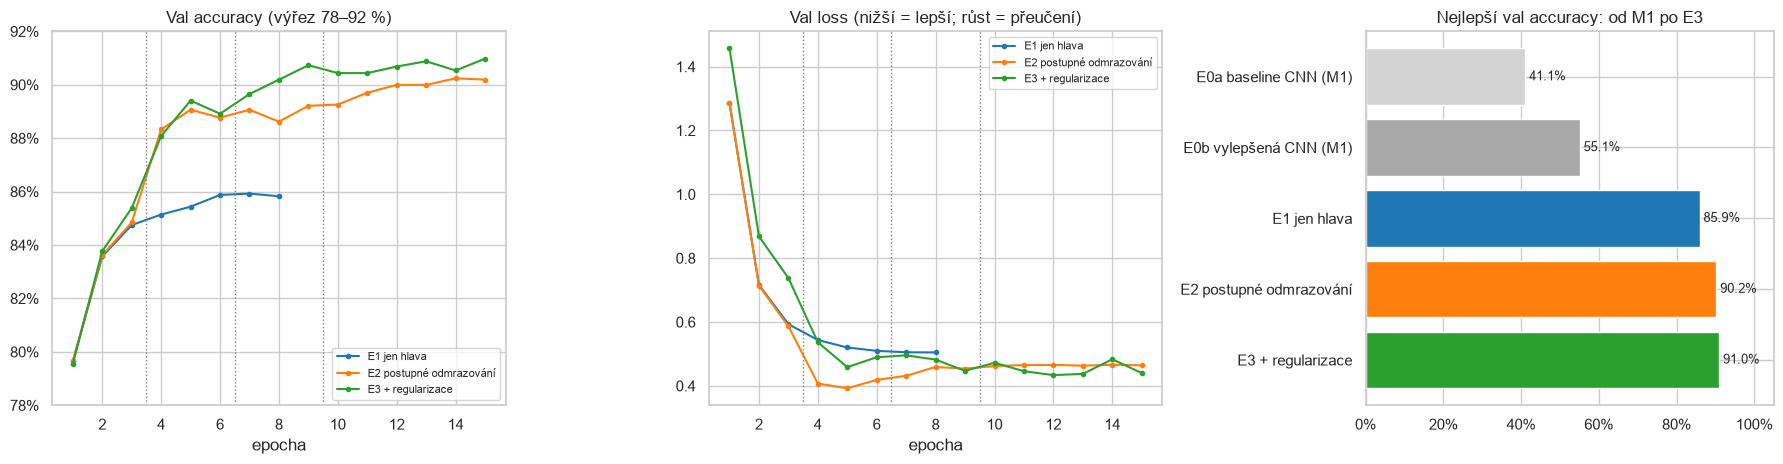

In [25]:
colors = {"E1 jen hlava": "tab:blue", "E2 postupné odmrazování": "tab:orange", "E3 + regularizace": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.9]})

for exp, log in logs.items():
    axes[0].plot(log["epoch"], log["val_acc"], "o-", ms=3, color=colors[exp], label=exp)
    axes[1].plot(log["epoch"], log["val_loss"], "o-", ms=3, color=colors[exp], label=exp)
for ax in axes[:2]:
    for e in (4, 7, 10):                                   # odmrazení v E2 a E3
        ax.axvline(e - 0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel("epocha"); ax.legend(fontsize=8)
axes[0].set_ylim(0.78, 0.92)
axes[0].yaxis.set_major_locator(plt.MultipleLocator(0.02))          # popisky po 2 %
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("Val accuracy (výřez 78–92 %)")
axes[1].set_title("Val loss (nižší = lepší; růst = přeučení)")

names = list(summary.index)
vals = summary["best val acc"].astype(float).values
bar_colors = ["lightgray", "darkgray"] + [colors[n] for n in names[2:]]
axes[2].barh(names[::-1], vals[::-1], color=bar_colors[::-1])
for i, v in enumerate(vals[::-1]):
    axes[2].text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=9)
axes[2].set_xlim(0, 1.05)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].set_title("Nejlepší val accuracy: od M1 po E3")

plt.tight_layout(); plt.show()

### 📝 Interpretace srovnání

**Co přineslo nejvíc:**

| Krok | Val accuracy | Přínos | Cena |
|---|---|---|---|
| E0b → E1: **předtrénované vlastnosti** (jen nová hlava) | 55,1 → 85,9 % | **+30,8 p. b.** | 4,4 min, jen 47 tis. trénovatelných parametrů |
| E1 → E2: **fine-tuning** (postupné odmrazování, různé lr) | 85,9 → 90,2 % | +4,3 p. b. | 3,5× delší trénink (15,2 min), 23,6 mil. parametrů |
| E2 → E3: **regularizace** | 90,2 → 91,0 % | +0,8 p. b. (nejisté) | čas stejný |

1. **Zdaleka nejefektivnější je samotný transfer learning.** Už zmrazená ResNet-50 s novou hlavou
   (47 tisíc trénovatelných parametrů, 4 minuty tréninku) je o 31 p. b. lepší než cokoliv, co jsme dokázali
   natrénovat od nuly. Vlastnosti naučené na 1,28 milionu obrázků ImageNetu nelze z našich 9,5 tisíce
   obrázků získat — tohle je hlavní poznatek celého projektu.
2. **Fine-tuning přidal dalších +4,3 p. b.**, z toho většinu hned odmrazení `layer4` (viz E2). Každý další
   odmrazený blok přidá méně a trénink zpomalí (epocha celé sítě je ~3,4× delší než epocha jen hlavy).
3. **Regularizace změnila hlavně chování modelu, ne přesnost:**
   - rozdíl train − val accuracy na konci: E2 **+8,6 p. b.** (přeučení) → E3 **−5,8 p. b.** (train je těžší
     než validace kvůli smíchaným obrázkům),
   - val loss v E2 od 5. epochy roste, v E3 ne — model z E3 je spolehlivější v tom, **jak moc si je jistý**,
   - přírůstek accuracy +0,8 p. b. je ale v rámci toho, co může způsobit náhoda jednoho běhu.

**Průběh učení (křivky):**
- Všechny tři experimenty jsou v prvních 3 epochách skoro totožné (všechny trénují jen hlavu) — rozdíly
  vznikají až po odmrazení `layer4` ⇒ ověřuje to, že změny mezi experimenty měří to, co měřit mají.
- E3 má v prvních epochách **vyšší val loss** než E1/E2 — label smoothing a míchání model učí odpovídat
  méně sebejistě, takže loss klesá pomaleji. Od 5. epochy je ale E3 v accuracy trvale nejlepší.
- E2 i E3 jsou na konci stále mírně rostoucí / stabilní — s cosine plánovačem, který lr na konci sníží
  téměř na nulu, se už ale velké zlepšení nedá čekat bez delšího tréninku.

➡️ **Nejlepší model je E3** — nejvyšší val accuracy a bez známek přeučení. Ten použijeme pro analýzu chyb
(Část 7) a jednorázové vyhodnocení na testu (Část 8).

# 🔍 Část 7 — Analýza chybných predikcí

Zkoumáme **nejlepší model (E3)** na **validační** sadě — test zůstává schovaný až na Část 8.
Postup od celku k detailu:

1. **Confusion matrix** — které dvojice tříd si model plete,
2. **accuracy po třídách** — které třídy zůstaly těžké a co jim pomohl fine-tuning (E1 vs. E3),
3. **obrázky s nejvyšší loss** — konkrétní případy, kde se model mýlí nejvíc (a nejsebejistěji),
4. **Grad-CAM** — kam se síť při rozhodování „dívala“.

Nejdřív spočítáme predikce pro celou validační sadu (bez augmentace, `eval_tf`). Pro každý obrázek si uložíme:
pravděpodobnosti všech tříd (softmax z logitů), predikovanou třídu a **loss tohoto jednoho obrázku**
(`reduction="none"` = loss se neprůměruje přes batch). Vysoká loss = model dal správné třídě malou pravděpodobnost.

### Modul `src/analysis.py`

- **`predict`** — logity a skutečné labely pro celou sadu (`model.eval()` + `torch.no_grad()`).
- **`GradCAM`** — heatmapa „kam se síť dívala“ (princip je vysvětlený u Grad-CAM níže). Technicky používá
  **hooky**: *forward hook* na bloku `layer4` si při průchodu sítí uloží jeho výstup a na tento výstup připojí
  *tensor hook*, který si při `backward()` uloží gradient. Metoda `remove()` hook po analýze odpojí.

In [26]:
%%writefile src/analysis.py
"""Analýza chyb pro Milestone 2: predikce pro celou sadu a Grad-CAM."""
import torch
import torch.nn.functional as F


def predict(model, loader, device):
    """Logity a skutečné labely pro celý loader (v pořadí loaderu — u val/test bez shuffle = pořadí v CSV)."""
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            all_logits.append(model(x.to(device)).cpu())
            all_labels.append(y)
    return torch.cat(all_logits), torch.cat(all_labels)


class GradCAM:
    """Grad-CAM: kam se síť „dívala“, když rozhodovala o dané třídě.

    1. Při průchodu sítí si uložíme výstup posledního konvolučního bloku (layer4: 2048 map 7 x 7).
       Každá mapa říká, KDE v obrázku je nějaký vzor.
    2. Spočítáme gradient skóre zvolené třídy podle těchto map. Průměr gradientu přes celou mapu = váha
       mapy: jak moc daný vzor zvyšuje skóre třídy.
    3. Vážený součet map (jen kladná část, ReLU) = heatmapa 7 x 7, kterou zvětšíme na velikost obrázku.
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handle = target_layer.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:       # pod torch.no_grad() gradient není (např. běžná predikce) — nic neukládat
            output.register_hook(lambda grad: setattr(self, "gradients", grad))   # gradient při backward()

    def remove(self):
        """Odpojí hook od modelu — po analýze se model chová zase úplně normálně."""
        self.handle.remove()

    def __call__(self, x, class_idx):
        """x: (1, 3, H, W) normalizovaný obrázek, class_idx: třída. Vrací heatmapu (H, W) v rozsahu 0–1."""
        self.model.eval()
        self.model.zero_grad()
        logits = self.model(x)
        logits[0, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)            # (1, 2048, 1, 1)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))  # (1, 1, 7, 7)
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        return (cam / (cam.max() + 1e-8)).detach().cpu()

Overwriting src/analysis.py


In [27]:
import importlib
import src.analysis
importlib.reload(src.analysis)
from src.analysis import GradCAM, predict

val_ds = SeaAnimalsDataset(splits["val"], eval_tf)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4)   # pořadí = splits["val"]

logits_e3, labels_val = predict(model_e3, val_loader, device)
probs_e3 = torch.softmax(logits_e3, dim=1)
preds_e3 = probs_e3.argmax(dim=1)
loss_e3 = nn.functional.cross_entropy(logits_e3, labels_val, reduction="none")    # loss každého obrázku

logits_e1, _ = predict(model_e1, val_loader, device)
preds_e1 = logits_e1.argmax(dim=1)

def per_class_acc(preds):
    correct = torch.bincount(labels_val[preds == labels_val], minlength=N_CLASSES)
    return (correct / torch.bincount(labels_val, minlength=N_CLASSES)).numpy()

acc_e1, acc_e3 = per_class_acc(preds_e1), per_class_acc(preds_e3)
print(f"E3: accuracy {(preds_e3 == labels_val).float().mean():.1%} | macro accuracy {acc_e3.mean():.1%} "
      f"| chyb {(preds_e3 != labels_val).sum().item()} z {len(labels_val)}")
print(f"E1: accuracy {(preds_e1 == labels_val).float().mean():.1%} | macro accuracy {acc_e1.mean():.1%}")

E3: accuracy 91.0% | macro accuracy 89.8% | chyb 184 z 2039
E1: accuracy 85.9% | macro accuracy 84.2%


## 🧮 Confusion matrix

Řádek = **skutečná** třída, sloupec = **predikovaná** třída. Hodnoty jsou **normalizované po řádcích**
(podíl obrázků dané třídy) — jinak by velké třídy (Turtle) přehlušily malé (Seal). Diagonála = správně,
vše mimo diagonálu = chyba. Pod maticí vypíšeme nejčastější záměny.

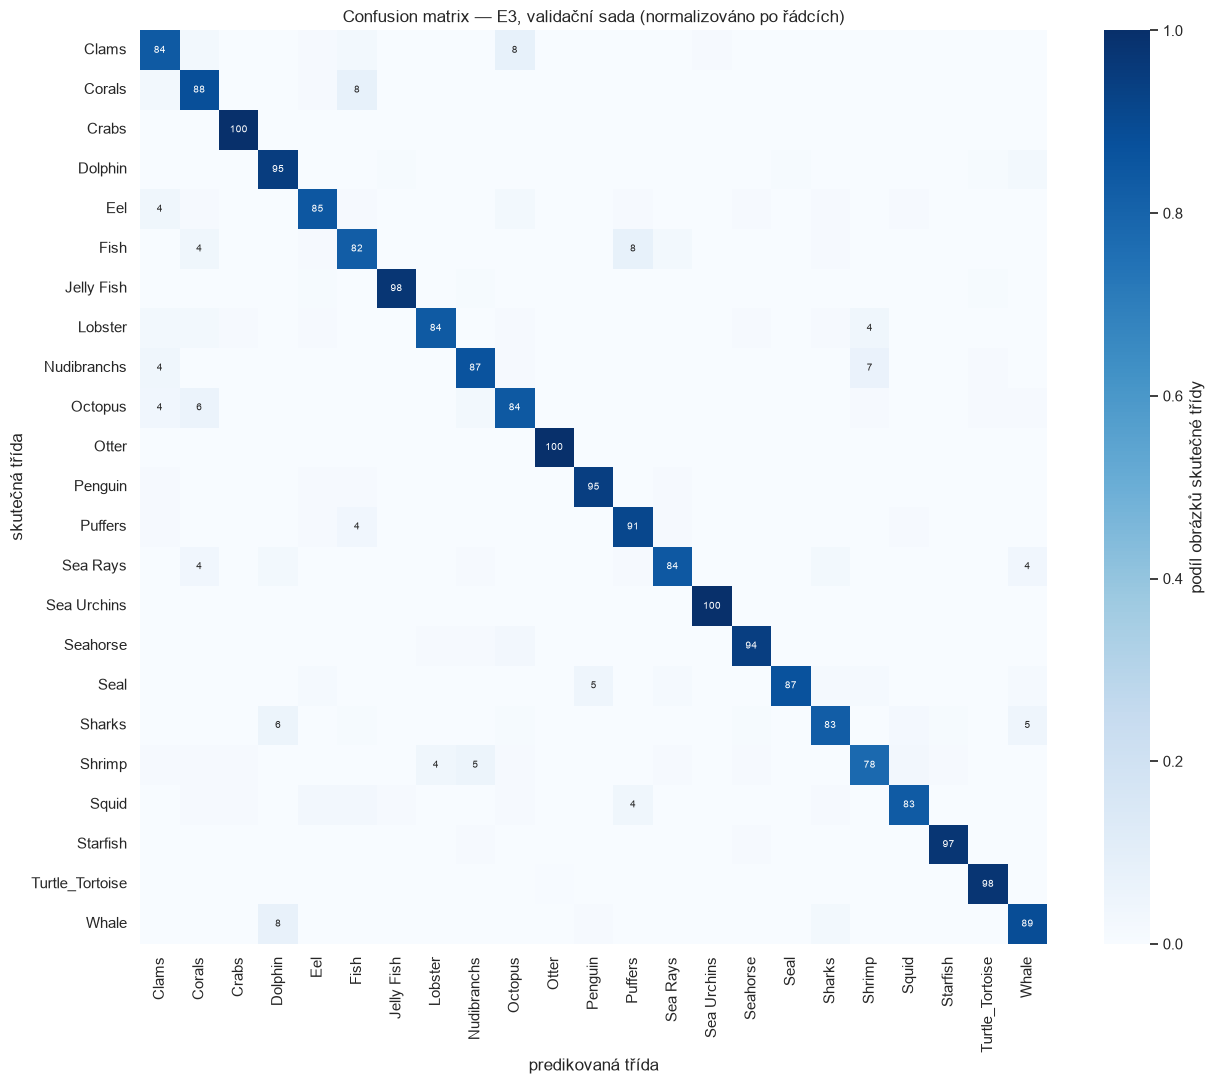

Nejčastější záměny (skutečná -> predikovaná):
  Fish             -> Puffers            6x  (8% obrázků třídy Fish)
  Clams            -> Octopus            6x  (8% obrázků třídy Clams)
  Corals           -> Fish               6x  (8% obrázků třídy Corals)
  Whale            -> Dolphin            6x  (8% obrázků třídy Whale)
  Nudibranchs      -> Shrimp             5x  (7% obrázků třídy Nudibranchs)
  Octopus          -> Corals             5x  (6% obrázků třídy Octopus)
  Sharks           -> Dolphin            5x  (6% obrázků třídy Sharks)
  Shrimp           -> Nudibranchs        4x  (5% obrázků třídy Shrimp)
  Sharks           -> Whale              4x  (5% obrázků třídy Sharks)
  Seal             -> Penguin            3x  (5% obrázků třídy Seal)


In [28]:
class_names = [idx_to_class[i] for i in range(N_CLASSES)]
cm = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
for t, p in zip(labels_val, preds_e3):
    cm[t, p] += 1
cm_norm = cm.float() / cm.sum(dim=1, keepdim=True)

# popisky v procentech jen pro hodnoty >= 3 % — jinak by byla matice nečitelná
annot = np.where(cm_norm.numpy() >= 0.03, (cm_norm.numpy() * 100).round().astype(int).astype(str), "")

plt.figure(figsize=(13, 11))
sns.heatmap(cm_norm.numpy(), xticklabels=class_names, yticklabels=class_names, cmap="Blues",
            vmin=0, vmax=1, annot=annot, fmt="", annot_kws={"fontsize": 7},
            cbar_kws={"label": "podíl obrázků skutečné třídy"})
plt.xlabel("predikovaná třída"); plt.ylabel("skutečná třída")
plt.title("Confusion matrix — E3, validační sada (normalizováno po řádcích)")
plt.tight_layout(); plt.show()

# nejčastější záměny (mimo diagonálu)
pairs = [(cm[t, p].item(), cm_norm[t, p].item(), class_names[t], class_names[p])
         for t in range(N_CLASSES) for p in range(N_CLASSES) if t != p and cm[t, p] > 0]
pairs.sort(reverse=True)
print("Nejčastější záměny (skutečná -> predikovaná):")
for n, frac, t, p in pairs[:10]:
    print(f"  {t:<16} -> {p:<16} {n:3d}x  ({frac:.0%} obrázků třídy {t})")

## ⚖️ Accuracy po třídách: E1 (jen hlava) vs. E3

Které třídy jsou nejtěžší a kterým nejvíc pomohl fine-tuning s regularizací?

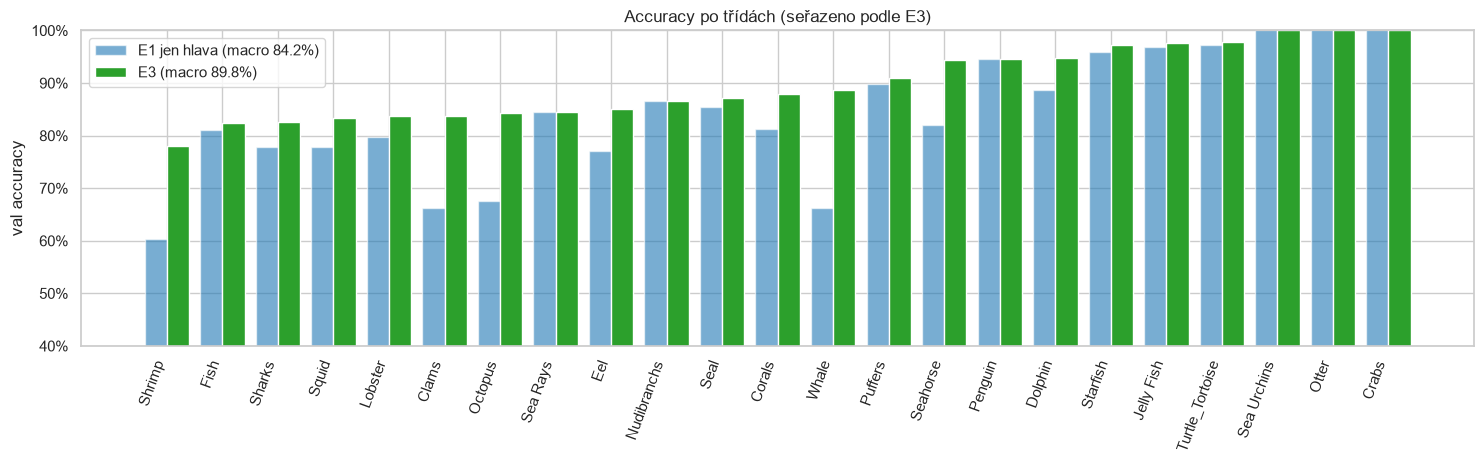

Nejhorší 5 tříd (E3): Shrimp 78%, Fish 82%, Sharks 83%, Squid 83%, Lobster 84%
Největší zlepšení E1 -> E3: Whale +22%, Shrimp +18%, Clams +18%, Octopus +17%, Seahorse +12%
Zhoršení E1 -> E3: žádné


In [29]:
order = np.argsort(acc_e3)
xpos = np.arange(N_CLASSES)
plt.figure(figsize=(15, 4.8))
plt.bar(xpos - 0.2, acc_e1[order], width=0.4, color="tab:blue", alpha=0.6, label=f"E1 jen hlava (macro {acc_e1.mean():.1%})")
plt.bar(xpos + 0.2, acc_e3[order], width=0.4, color="tab:green", label=f"E3 (macro {acc_e3.mean():.1%})")
plt.xticks(xpos, [class_names[i] for i in order], rotation=70, ha="right")
plt.ylim(0.4, 1.0); plt.ylabel("val accuracy"); plt.legend()
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.title("Accuracy po třídách (seřazeno podle E3)")
plt.tight_layout(); plt.show()

diff = acc_e3 - acc_e1
print("Nejhorší 5 tříd (E3):", ", ".join(f"{class_names[i]} {acc_e3[i]:.0%}" for i in order[:5]))
print("Největší zlepšení E1 -> E3:", ", ".join(f"{class_names[i]} {diff[i]:+.0%}" for i in np.argsort(-diff)[:5]))
print("Zhoršení E1 -> E3:", ", ".join(f"{class_names[i]} {diff[i]:+.0%}" for i in np.argsort(diff) if diff[i] < 0) or "žádné")

## 💥 Obrázky s nejvyšší loss

Seřadíme validační obrázky podle loss a zobrazíme **10 nejhorších**. Vysoká loss znamená, že model dal
**skutečné** třídě velmi malou pravděpodobnost — tedy se spletl a byl si přitom jistý. U každého obrázku
vidíme skutečnou třídu, predikci s pravděpodobností a pravděpodobnost, kterou model dal správné třídě.

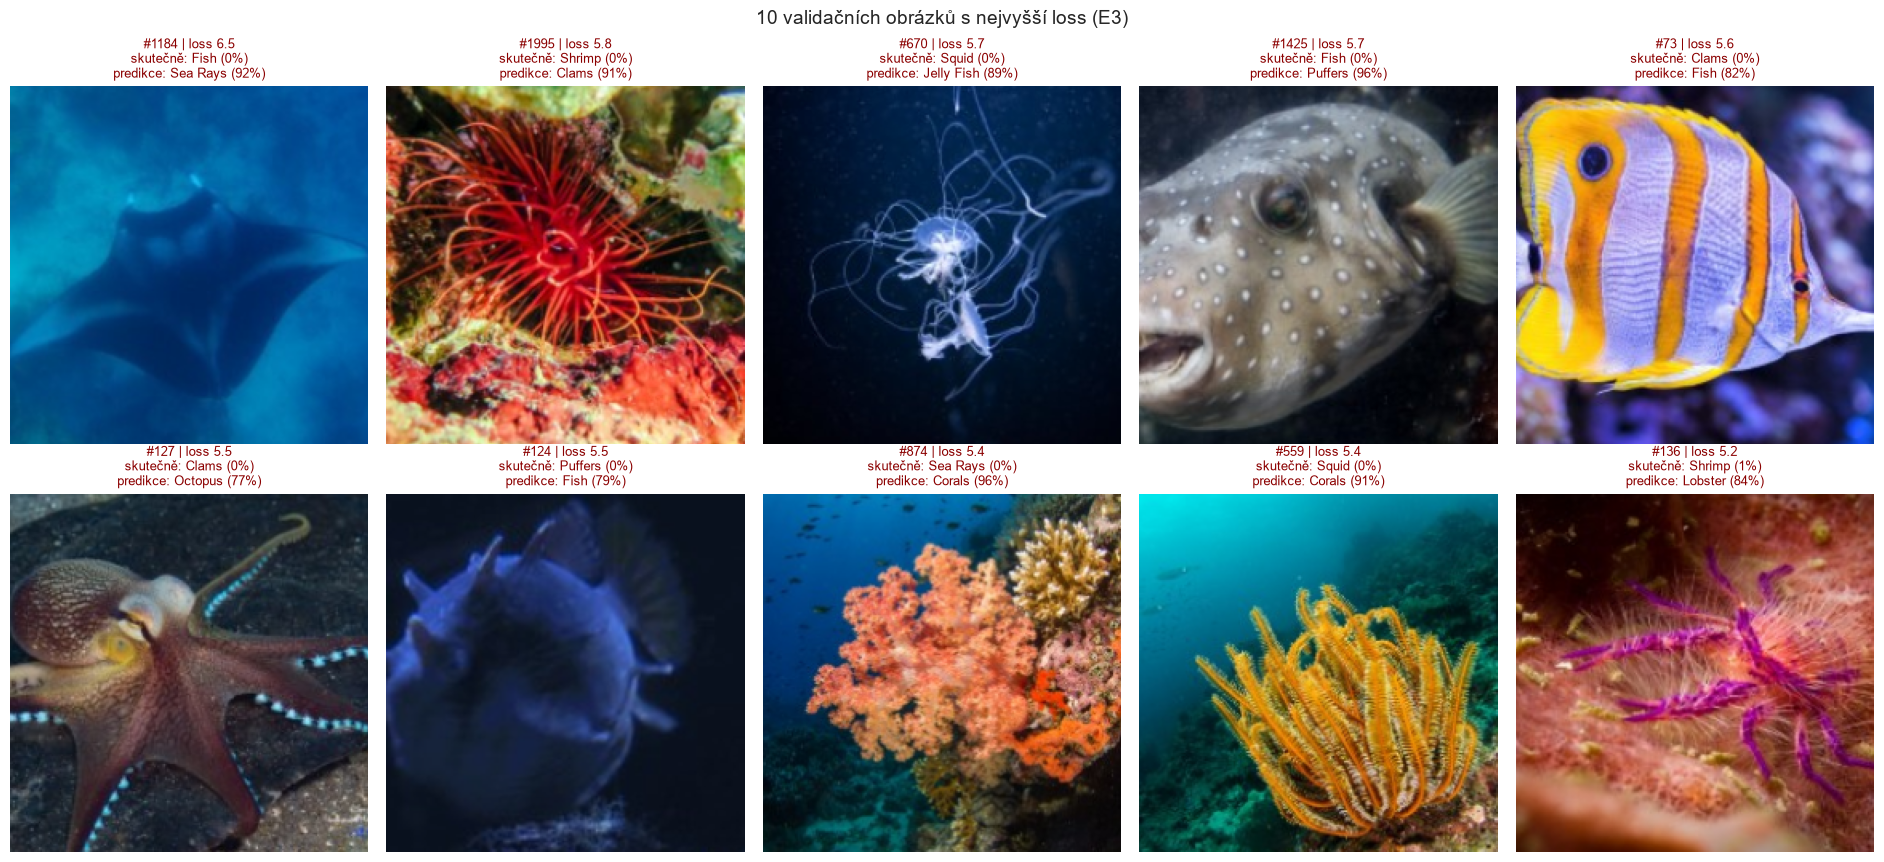

,path,label,predikce,p(predikce),p(skutečná),loss
1184,data/sea_animals/Fish/3881306440_7e3e062b9c_o.jpg,Fish,Sea Rays,0.92,0.002,6.48
1995,data/sea_animals/Shrimp/29560600850_e89f24be39...,Shrimp,Clams,0.91,0.003,5.80
670,data/sea_animals/Squid/19106791720_eac4e02420_...,Squid,Jelly Fish,0.89,0.003,5.71
1425,data/sea_animals/Fish/8194543885_be647a3c3e_b.jpg,Fish,Puffers,0.96,0.003,5.69
73,data/sea_animals/Clams/24776656826_b6574bb25d_...,Clams,Fish,0.82,0.004,5.61
127,data/sea_animals/Clams/23902282458_1c1a24daf7_...,Clams,Octopus,0.77,0.004,5.47
124,data/sea_animals/Puffers/5484339429_19d7773c10...,Puffers,Fish,0.79,0.004,5.46
874,data/sea_animals/Sea Rays/28254930541_e10618ec...,Sea Rays,Corals,0.96,0.004,5.44
559,data/sea_animals/Squid/31782199451_6d5d8aaa89_...,Squid,Corals,0.91,0.005,5.36
136,data/sea_animals/Shrimp/12644313885_f60ecc15bc...,Shrimp,Lobster,0.84,0.005,5.25


In [30]:
TOP_K = 10
worst = torch.argsort(loss_e3, descending=True)[:TOP_K]

fig, axes = plt.subplots(2, 5, figsize=(19, 9))
for ax, i in zip(axes.ravel(), worst.tolist()):
    img, y = val_ds[i]
    p = preds_e3[i].item()
    ax.imshow(denormalize(img)); ax.axis("off")
    ax.set_title(f"#{i} | loss {loss_e3[i]:.1f}\nskutečně: {class_names[y]} ({probs_e3[i, y]:.0%})\n"
                 f"predikce: {class_names[p]} ({probs_e3[i, p]:.0%})", fontsize=9,
                 color="darkred")
plt.suptitle("10 validačních obrázků s nejvyšší loss (E3)", fontsize=14)
plt.tight_layout(); plt.show()

worst_df = splits["val"].loc[worst.numpy(), ["path", "label"]].copy()
worst_df["predikce"] = [class_names[preds_e3[i]] for i in worst.tolist()]
worst_df["p(predikce)"] = [f"{probs_e3[i, preds_e3[i]]:.2f}" for i in worst.tolist()]
worst_df["p(skutečná)"] = [f"{probs_e3[i, labels_val[i]]:.3f}" for i in worst.tolist()]
worst_df["loss"] = [f"{loss_e3[i]:.2f}" for i in worst.tolist()]
worst_df

## 🔥 Grad-CAM — kam se síť dívala

**Grad-CAM** ukazuje, které části obrázku nejvíc zvýšily skóre dané třídy. Používá výstup posledního
konvolučního bloku `layer4` (2 048 map o velikosti 7 × 7 — každá říká, *kde* v obrázku je nějaký vzor) a gradient
skóre třídy podle těchto map (*jak moc* daný vzor třídě pomáhá). Vážený součet map dá hrubou heatmapu 7 × 7,
kterou zvětšíme na 224 × 224 a položíme přes obrázek. Červená = oblasti, podle kterých se síť rozhodla.

Pro 5 nejhorších obrázků zobrazíme heatmapu pro **predikovanou** třídu (proč si síť myslela, že je to X)
a pro **skutečnou** třídu (kde viděla důkazy pro správnou odpověď).

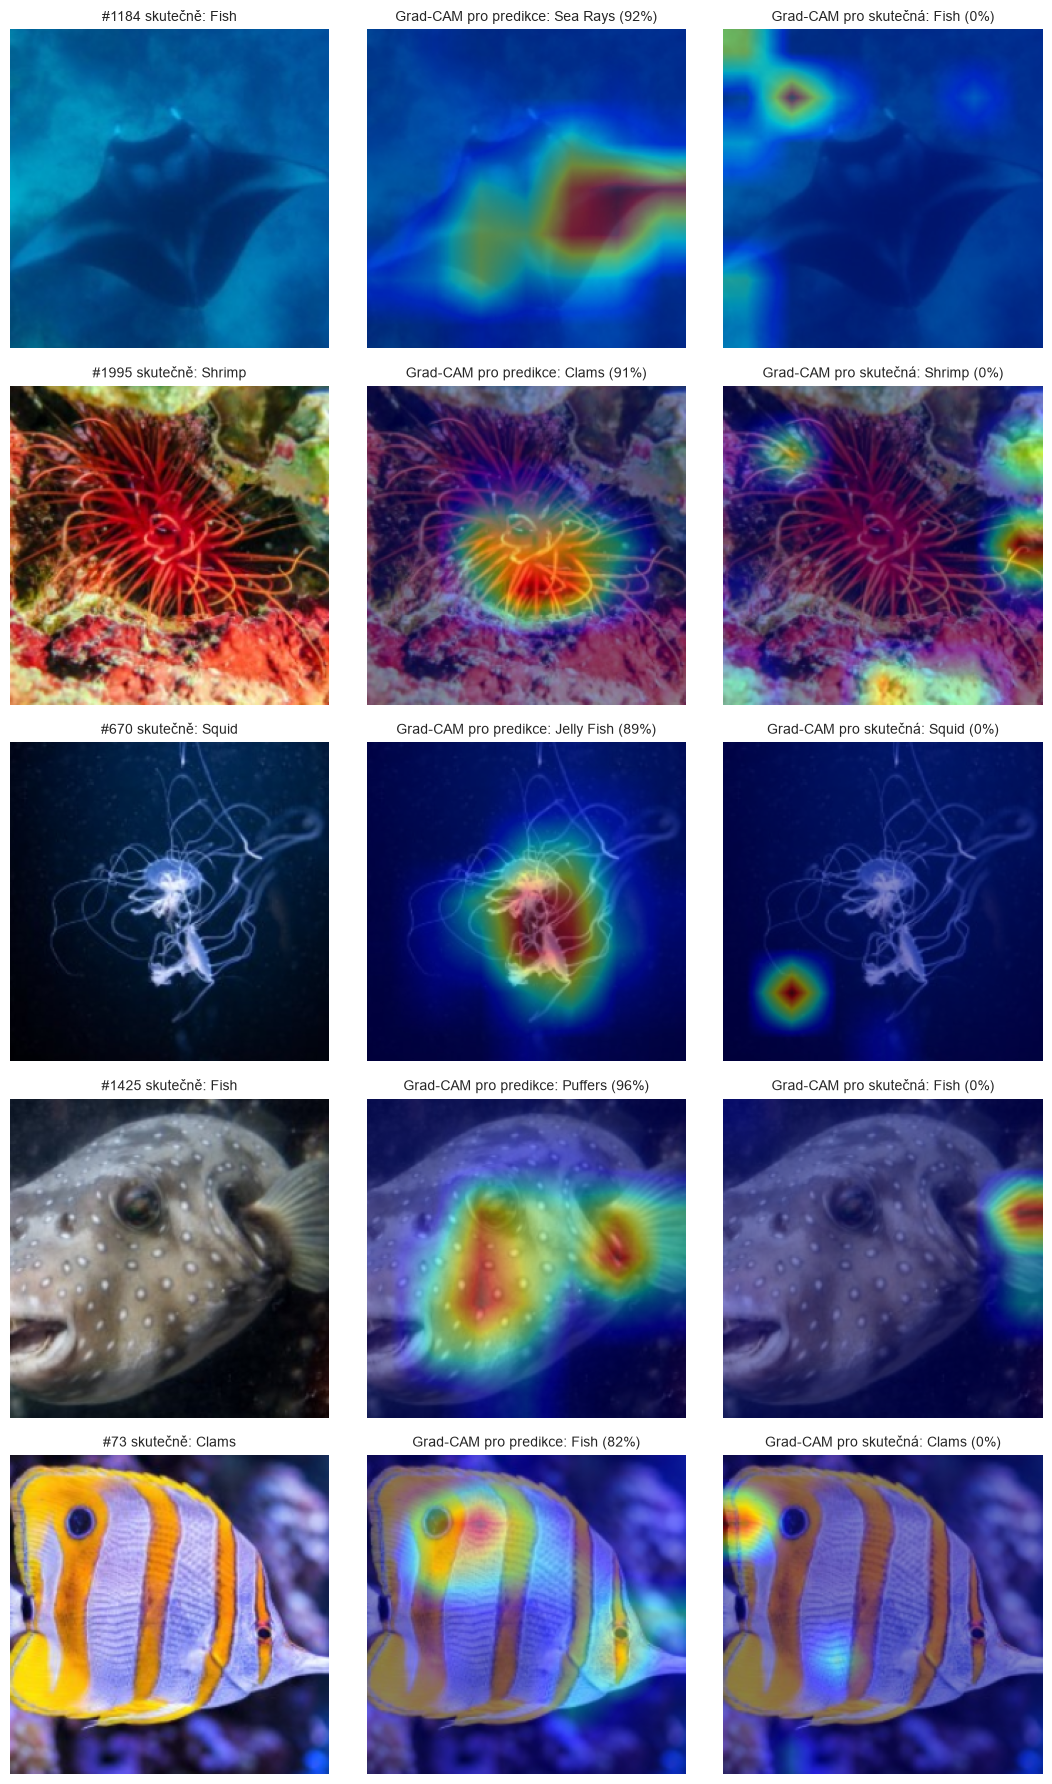

In [31]:
cam = GradCAM(model_e3, model_e3.layer4)

fig, axes = plt.subplots(5, 3, figsize=(11, 18))
for row, i in enumerate(worst[:5].tolist()):
    img, y = val_ds[i]
    p = preds_e3[i].item()
    x = img.unsqueeze(0).to(device)
    shown = denormalize(img)
    axes[row, 0].imshow(shown); axes[row, 0].set_title(f"#{i} skutečně: {class_names[y]}", fontsize=10)
    for col, (cls, label) in enumerate([(p, "predikce"), (y, "skutečná")], start=1):
        heat = cam(x, cls)
        axes[row, col].imshow(shown)
        axes[row, col].imshow(heat, cmap="jet", alpha=0.45)
        axes[row, col].set_title(f"Grad-CAM pro {label}: {class_names[cls]} ({probs_e3[i, cls]:.0%})", fontsize=10)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout(); plt.show()
cam.remove()                      # odpojit Grad-CAM, aby neovlivňoval další použití modelu

### 📝 Interpretace chyb

**Celkově:** model E3 se na validaci mýlí u **184 z 2 039** obrázků (accuracy 91,0 %, macro accuracy 89,8 %).
Proti E1 se zlepšila **každá** třída, nejvíc Whale (+22 p. b.), Shrimp, Clams (+18) a Octopus (+17) —
tedy třídy, kde nestačily obecné vlastnosti z ImageNetu a bylo potřeba síť doladit. Nejtěžší zůstávají
Shrimp (78 %), Fish (82 %), Sharks, Squid (83 %) a Lobster (84 %).

#### 🧮 Confusion matrix — typy záměn
| Záměna | Podíl | Pravděpodobná příčina |
|---|---|---|
| Fish → Puffers | 8 % | **překrývající se třídy** — čtverzubec *je* ryba; dataset ho ale vede zvlášť |
| Whale → Dolphin, Sharks → Dolphin / Whale | 5–8 % | podobná silueta: šedé, protáhlé tělo ve vodním sloupci, často z dálky nebo zespodu |
| Clams → Octopus, Octopus → Corals | 6–8 % | **maskování** — chobotnice napodobuje okolí (korály, mušle), a naopak |
| Corals → Fish | 8 % | **více objektů v záběru** — fotky útesu často obsahují i ryby; který label je „správný“? |
| Nudibranchs ↔ Shrimp | 5–7 % | drobní, pestře zbarvení bezobratlí s výrůstky, často na podobném podkladu |
| Seal → Penguin | 5 % | obojí na skalách / u hladiny, podobné zbarvení (černobílá / šedá) |

Chyby tedy nejsou náhodné — síť si plete třídy, které se **opravdu podobají** nebo se v datasetu **překrývají**.

#### 💥 10 obrázků s nejvyšší loss — co se ve skutečnosti stalo
Při prohlédnutí obrázků se ukazuje, že **většina „nejhorších chyb“ nejsou chyby modelu, ale chyby v datasetu**:

| Typ | Obrázky | Popis |
|---|---|---|
| **Špatný label — model má pravdu** | #73, #127, #670, #874 | pruhovaná ryba (klipka) označená jako *Clams*; chobotnice jako *Clams*; medúza jako *Squid*; korálový útes bez rejnoka jako *Sea Rays*. Model ve všech případech předpověděl **správné** zvíře s 77–96% jistotou |
| **Překrývající se třídy** | #1184, #1425, #124 | manta označená jako *Fish* (model: *Sea Rays*), čtverzubec jako *Fish* (model: *Puffers*) a naopak tmavý čtverzubec jako *Puffers* (model: *Fish*). Rejnoci i čtverzubci **jsou ryby** — dataset ale má pro ně vlastní třídy, takže obě odpovědi jsou svým způsobem správně |
| **Zvíře mimo všechny třídy** | #1995, #559, #136 | sasanka (*Shrimp*), lilijice (*Squid*), chlupatý krabík na houbě (*Shrimp*). Žádná z 23 tříd nepasuje — model zvolil vizuálně nejpodobnější (*Clams*, *Corals*, *Lobster*) |

**Proč je u nich loss tak vysoká:** model si je svou (často správnou) odpovědí jistý na 77–96 %, takže „skutečné“
třídě z labelu dá jen ~0,3 % ⇒ loss = −ln(0,003) ≈ 5,8. Nejvyšší loss tak paradoxně ukazuje hlavně na
**chybně označená data**.

#### 🔥 Grad-CAM
- U predikované třídy se síť dívá **na samotné zvíře** — tělo a křídla manty, zvon medúzy, tělo a oko čtverzubce,
  hlavu klipky. Nerozhoduje se podle pozadí (barvy vody, písku) — to je dobrá zpráva: model se nenaučil
  „zkratku“ typu *modrá voda = žralok*.
- U „skutečné“ třídy z labelu heatmapa svítí na okrajích nebo prázdném pozadí — síť v obrázku **nenašla nic**,
  co by třídu podporovalo. U chybných labelů je to přesně očekávané chování.

#### 💡 Závěry
1. **Část chyb jde na vrub kvality datasetu**, ne modelu ⇒ skutečná přesnost modelu je spíš o něco **vyšší**,
   než ukazuje 91 %. Seznam obrázků s nejvyšší loss je velmi efektivní nástroj na **hledání chybných labelů**.
2. **Překrývající se třídy** (Fish vs. Puffers / Sea Rays / Sharks) jsou problém zadání úlohy — řešením by byla
   hierarchie tříd nebo jasnější definice „Fish“ = ostatní ryby.
3. **Možná zlepšení:** vyčistit labely (ručně projít např. 100 obrázků s nejvyšší loss v trénovací sadě),
   vyšší rozlišení pro drobné bezobratlé (Shrimp, Nudibranchs), víc dat pro podobné dvojice (Whale / Dolphin).

# 🏁 Část 8 — Vyhodnocení na testu a finální shrnutí

## 🧾 Testovací sada

Testovací sadu (2 040 obrázků) jsme **dosud nepoužili** — všechna rozhodnutí (architektura, plán odmrazování,
regularizace, výběr nejlepší epochy, analýza chyb) padla podle validační sady. Test je proto **nezávislý odhad**,
jak modely fungují na úplně nových obrázcích.

Vyhodnocujeme ho **jednou**, pro všechny tři experimenty najednou (každý s vahami z nejlepší epochy podle
validace), a podle výsledku už nic neměníme. Kromě accuracy počítáme i **macro accuracy** (průměr přes třídy —
každá třída má stejnou váhu) a test loss.

In [32]:
test_loader = DataLoader(SeaAnimalsDataset(splits["test"], eval_tf), batch_size=64, shuffle=False, num_workers=4)

def test_metrics(model):
    logits, labels = predict(model, test_loader, device)
    preds = logits.argmax(dim=1)
    correct = torch.bincount(labels[preds == labels], minlength=N_CLASSES)
    per_class = correct / torch.bincount(labels, minlength=N_CLASSES)
    return {"test acc": (preds == labels).float().mean().item(),
            "test macro acc": per_class.mean().item(),
            "test loss": nn.functional.cross_entropy(logits, labels).item()}

test_rows = {
    "E0a baseline CNN (M1)":  {"test acc": 0.395, "test macro acc": 0.359, "test loss": 3.257},
    "E0b vylepšená CNN (M1)": {"test acc": 0.566, "test macro acc": 0.541, "test loss": 1.427},
}
for exp, m in [("E1 jen hlava", model_e1), ("E2 postupné odmrazování", model_e2), ("E3 + regularizace", model_e3)]:
    test_rows[exp] = test_metrics(m)

final = pd.DataFrame(test_rows).T
final.insert(0, "best val acc", summary["best val acc"].astype(float))
final.style.format({"best val acc": "{:.1%}", "test acc": "{:.1%}", "test macro acc": "{:.1%}", "test loss": "{:.3f}"})

,best val acc,test acc,test macro acc,test loss
E0a baseline CNN (M1),41.1%,39.5%,35.9%,3.257
E0b vylepšená CNN (M1),55.1%,56.6%,54.1%,1.427
E1 jen hlava,85.9%,87.2%,85.3%,0.488
E2 postupné odmrazování,90.2%,90.3%,89.2%,0.429
E3 + regularizace,91.0%,90.7%,89.5%,0.433


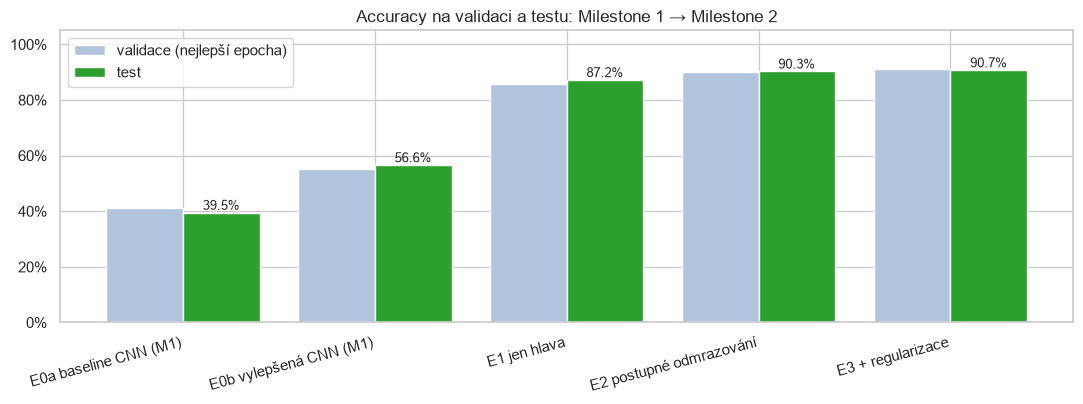

In [33]:
fig, ax = plt.subplots(figsize=(11, 4.2))
xpos = np.arange(len(final))
ax.bar(xpos - 0.2, final["best val acc"], width=0.4, color="lightsteelblue", label="validace (nejlepší epocha)")
ax.bar(xpos + 0.2, final["test acc"], width=0.4, color="tab:green", label="test")
for x, v in zip(xpos, final["test acc"]):
    ax.text(x + 0.2, v + 0.01, f"{v:.1%}", ha="center", fontsize=9)
ax.set_xticks(xpos, final.index, rotation=15, ha="right")
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Accuracy na validaci a testu: Milestone 1 → Milestone 2"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 📝 Finální shrnutí

### 🧾 Výsledky na testovací sadě (2 040 obrázků, 23 tříd)

| Model | Trénovatelných parametrů | Čas tréninku | Val acc | **Test acc** | **Test macro acc** | Test loss |
|---|---|---|---|---|---|---|
| E0a baseline CNN od nuly (M1) | 0,40 mil. | ~2 min | 41,1 % | 39,5 % | 35,9 % | 3,26 |
| E0b vylepšená CNN od nuly (M1) | 1,18 mil. | ~7 min | 55,1 % | 56,6 % | 54,1 % | 1,43 |
| E1 ResNet-50, jen hlava | 0,05 mil. | 4,4 min | 85,9 % | 87,2 % | 85,3 % | 0,49 |
| E2 + postupné odmrazování, různé lr | 23,6 mil. | 15,2 min | 90,2 % | 90,3 % | 89,2 % | 0,43 |
| **E3 + CutMix/Mixup, Random Erasing, label smoothing** | 23,6 mil. | 15,2 min | **91,0 %** | **90,7 %** | **89,5 %** | 0,43 |

**Finální model (E3) dosáhl 90,7 % accuracy na testu — o 34 p. b. víc než nejlepší síť z Milestone 1.**
Výsledky na testu odpovídají validaci (u experimentů M2 rozdíl do 1,3 p. b.) ⇒ validační sada byla spolehlivým vodítkem
a výběrem experimentů ani epoch jsme se jí nepřizpůsobili.

### 🥇 Co bylo nejefektivnější
1. **Samotný transfer learning** (E0b → E1): **+30,6 p. b. na testu** za 4 minuty tréninku a 47 tisíc
   trénovatelných parametrů. Vlastnosti, které se ResNet-50 naučila na 1,28 milionu obrázků ImageNetu,
   se z našich 9,5 tisíce obrázků naučit nedají. Tohle je zdaleka nejdůležitější rozhodnutí celého projektu.
2. **Odmrazení `layer4`** — nejvyšší blok sítě (64 % parametrů) přinesl většinu zisku z fine-tuningu
   (+4 p. b. na validaci, z toho +3,5 p. b. hned v první epoše po odmrazení). Další bloky přidaly už jen ~1 p. b.
   a trénink zpomalily 2,5×.
3. **Postupné odmrazování s různými learning rate + warmup/cosine** — síť se doladila bez „zapomenutí“
   předtrénovaných vlastností: přesnost po každém odmrazení rostla, nikdy nespadla.

### ⚠️ Co bylo nejproblematičtější
1. **Kvalita datasetu.** Analýza chyb ukázala, že většina obrázků s nejvyšší loss má **chybný label**
   (medúza jako *Squid*, chobotnice jako *Clams*…), třídy se **překrývají** (*Puffers* a *Sea Rays* jsou také
   ryby, ale *Fish* je samostatná třída) nebo zvíře **nepatří do žádné třídy** (sasanka, lilijice).
   Část zbývajících ~9 % chyb tedy není chyba modelu a skutečná přesnost je spíš vyšší.
2. **Přeučení při plném fine-tuningu** (E2: train 98,8 % vs. val 90 %, rostoucí val loss). Regularizace v E3
   ho **odstranila**, přesnost ale zvedla jen málo (+0,8 p. b. na validaci, **+0,4 p. b. na testu** ⇒ v rámci
   náhody jednoho běhu). Hlavní přínos regularizace je tedy v **chování** modelu (není přehnaně sebejistý),
   ne v přesnosti — model už byl blízko stropu, který ResNet-50 na 224 px a tomto datasetu umožňuje.
3. **Výpočetní limity GTX 1080:** plný fine-tuning ResNet-50 zabere 6,3 z 8 GB paměti (proto batch 32)
   a je 3,4× pomalejší než trénink hlavy. Mixed precision na kartě bez tensor cores nepomůže.
4. **Vizuálně podobné třídy:** Whale ↔ Dolphin ↔ Sharks (silueta), Clams ↔ Octopus ↔ Corals (maskování),
   Nudibranchs ↔ Shrimp (drobní bezobratlí). Tyto záměny přetrvaly i u nejlepšího modelu.

### 💡 Zajímavé poznatky
- **Nejvyšší loss = nejlepší detektor chybných labelů.** Když je model správně a sebejistě, „skutečná“ třída
  z labelu dostane ~0,3 % ⇒ loss ~6. Ruční kontrola obrázků s nejvyšší loss je velmi levný způsob, jak dataset vyčistit.
- **Grad-CAM potvrdil, že se síť dívá na zvíře, ne na pozadí** (tělo manty, zvon medúzy, oko a tělo čtverzubce) —
  nenaučila se zkratky typu „modrá voda = žralok“.
- **U regularizovaného modelu je train accuracy nižší než validační** (85 % vs. 91 %) — není to chyba:
  trénovací obrázky jsou smíchané (CutMix / Mixup) a částečně vymazané, validační čisté.
- **Normalizace podle ImageNetu je nutná** — předtrénovaná síť „čeká“ vstupy v rozsahu, ve kterém se učila.
- **Zlepšila se každá třída** (E1 → E3), nejvíc ty, kde obecné vlastnosti z ImageNetu nestačily
  (Whale +22 p. b., Shrimp a Clams +18 p. b.).

### 🔁 Reprodukovatelnost
Každý experiment má v `runs/<jméno>/` uloženou **konfiguraci** (`config.json`) a **log po epochách** (`log.csv`).
Pevný seed, deterministické cuDNN a split uložený v `splits/` zajišťují, že `fit(config, ...)` dá stejná čísla.
Natrénované váhy (`best.pt`, ~95 MB na experiment) nejsou v gitu — bez nich se experiment při spuštění
notebooku natrénuje znovu (celkem ~35 minut na GTX 1080).

### ➡️ Co by šlo zkusit dál
- **Vyčistit labely** (projít obrázky s nejvyšší loss v trénovací sadě) a ujasnit překrývající se třídy.
- **Delší trénink** E3 (model se v poslední epoše ještě zlepšoval) a vyšší rozlišení pro drobné bezobratlé.
- **Modernější backbone** (ConvNeXt, EfficientNetV2) — při 8 GB paměti GPU ale jen menší varianty.